In [64]:
from IPython.display import Markdown, display

display(Markdown("""
# A Proximity-Based Early Warning System for Gentrification in California

## Machine Learning Mini-Project

### Problem Statement

Gentrification is a complex socioeconomic process that can cause significant changes in housing costs, income distributions, and neighborhood characteristics.

This project investigates whether machine-learning models can provide an early warning signal for gentrification at the California Census Tract level.

The approach uses historical housing and socioeconomic features together with proximity-based spatial features to predict whether a Census Tract is classified as gentrifying.

### Main Objectives

1. Develop machine-learning models for binary gentrification classification.
2. Compare Logistic Regression, Random Forest, and XGBoost-based approaches.
3. Investigate whether proximity-based spatial features provide useful predictive information.
4. Evaluate the selected model on an unseen test dataset.
5. Analyze the limitations and generalization of the resulting model.

### Key Result

Random Forest achieved the strongest validation performance with a ROC-AUC of **0.5937**.

The proximity ablation experiment showed that removing the proximity features reduced Random Forest validation ROC-AUC from **0.5937 to 0.4888**.

However, the final model achieved a test ROC-AUC of **0.5125**, indicating weak generalization to unseen data.

### Project Type

**Binary Classification + Spatial/Proximity Feature Analysis**
"""))


# A Proximity-Based Early Warning System for Gentrification in California

## Machine Learning Mini-Project

### Problem Statement

Gentrification is a complex socioeconomic process that can cause significant changes in housing costs, income distributions, and neighborhood characteristics.

This project investigates whether machine-learning models can provide an early warning signal for gentrification at the California Census Tract level.

The approach uses historical housing and socioeconomic features together with proximity-based spatial features to predict whether a Census Tract is classified as gentrifying.

### Main Objectives

1. Develop machine-learning models for binary gentrification classification.
2. Compare Logistic Regression, Random Forest, and XGBoost-based approaches.
3. Investigate whether proximity-based spatial features provide useful predictive information.
4. Evaluate the selected model on an unseen test dataset.
5. Analyze the limitations and generalization of the resulting model.

### Key Result

Random Forest achieved the strongest validation performance with a ROC-AUC of **0.5937**.

The proximity ablation experiment showed that removing the proximity features reduced Random Forest validation ROC-AUC from **0.5937 to 0.4888**.

However, the final model achieved a test ROC-AUC of **0.5125**, indicating weak generalization to unseen data.

### Project Type

**Binary Classification + Spatial/Proximity Feature Analysis**


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries loaded successfully!")

All libraries loaded successfully!


print("Gentrification ML Project Started")


In [3]:
import pandas as pd
from google.colab import files

# Upload the dataset from your computer
uploaded = files.upload()

# Load the uploaded CSV file
file_path = "california_gentrification_final_model_ready.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Saving california_gentrification_final_model_ready.csv to california_gentrification_final_model_ready.csv
Dataset loaded successfully!
Rows: 7965
Columns: 167


In [4]:
pd.set_option("display.max_rows", None)

print("Column names:")
for i, column in enumerate(df.columns, start=1):
    print(i, ":", column)

Column names:
1 : tract_id
2 : state_fips
3 : county_fips
4 : tract_code
5 : delta_2010_2011_DP2_HC01_VC03
6 : delta_2010_2011_DP2_HC01_VC07
7 : delta_2010_2011_DP2_HC01_VC10
8 : delta_2010_2011_DP2_HC01_VC13
9 : delta_2010_2011_DP2_HC01_VC17
10 : delta_2010_2011_DP2_HC01_VC21
11 : delta_2010_2011_DP2_HC01_VC27
12 : delta_2010_2011_DP2_HC01_VC30
13 : delta_2010_2011_DP2_HC01_VC36
14 : delta_2010_2011_DP2_HC01_VC39
15 : delta_2010_2011_DP2_HC01_VC43
16 : delta_2010_2011_DP2_HC01_VC46
17 : delta_2010_2011_DP2_HC01_VC52
18 : delta_2010_2011_DP2_HC01_VC55
19 : delta_2010_2011_DP2_HC01_VC61
20 : delta_2010_2011_DP2_HC01_VC65
21 : delta_2010_2011_DP2_HC01_VC69
22 : delta_2010_2011_DP2_HC01_VC75
23 : delta_2010_2011_DP2_HC01_VC78
24 : delta_2010_2011_DP2_HC01_VC84
25 : delta_2010_2011_DP2_HC01_VC87
26 : delta_2010_2011_DP2_HC01_VC90
27 : delta_2010_2011_DP2_HC01_VC99
28 : delta_2010_2011_DP2_HC01_VC119
29 : delta_2010_2011_DP2_HC01_VC122
30 : delta_2010_2011_DP2_HC01_VC128
31 : delta_2010_201

In [5]:
print("\nLAST 30 COLUMNS:")
for i, column in enumerate(df.columns[-30:], start=len(df.columns)-29):
    print(i, ":", column)


LAST 30 COLUMNS:
138 : delta_2010_2011_DP5_HC01_VC34
139 : delta_2010_2011_DP5_HC01_VC40
140 : delta_2010_2011_DP5_HC01_VC44
141 : delta_2010_2011_DP5_HC01_VC47
142 : delta_2010_2011_DP5_HC01_VC50
143 : delta_2010_2011_DP5_HC01_VC53
144 : delta_2010_2011_DP5_HC01_VC56
145 : delta_2010_2011_DP5_HC01_VC59
146 : delta_2010_2011_DP5_HC01_VC62
147 : delta_2010_2011_DP5_HC01_VC65
148 : delta_2010_2011_DP5_HC01_VC68
149 : delta_2010_2011_DP5_HC01_VC73
150 : delta_2010_2011_DP5_HC01_VC76
151 : delta_2010_2011_DP5_HC01_VC82
152 : delta_2010_2011_DP5_HC01_VC85
153 : delta_2010_2011_DP5_HC01_VC88
154 : delta_2010_2011_DP5_HC01_VC91
155 : housing_cost_response
156 : housing_gentrification_score
157 : housing_gentrification_label
158 : income_hellinger_response
159 : income_gentrification_score
160 : income_gentrification_label
161 : spatial_lag_housing_pre2012
162 : local_morans_I_housing_pre2012
163 : spatial_lag_income_pre2012
164 : local_morans_I_income_pre2012
165 : pre_housing_change
166 : p

In [6]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes.value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset shape: (7965, 167)

Data types:
float64    160
int64        6
object       1
Name: count, dtype: int64

Missing values:
553

Duplicate rows:
0


In [7]:
print("Housing gentrification label counts:")
print(df["housing_gentrification_label"].value_counts())

print("\nHousing gentrification label percentages:")
print(
    df["housing_gentrification_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Housing gentrification label counts:
housing_gentrification_label
1    4132
0    3833
Name: count, dtype: int64

Housing gentrification label percentages:
housing_gentrification_label
1    51.88
0    48.12
Name: proportion, dtype: float64


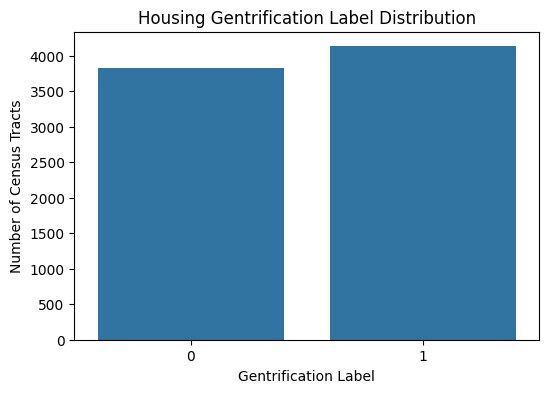

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="housing_gentrification_label"
)

plt.title("Housing Gentrification Label Distribution")
plt.xlabel("Gentrification Label")
plt.ylabel("Number of Census Tracts")

plt.show()

In [9]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Columns with missing values:")
print(missing)

Columns with missing values:
pre_housing_change    546
pre_income_change       7
dtype: int64


In [10]:
# ==============================
# STEP 1: PREPARE DATA
# ==============================

# Target
target = "housing_gentrification_label"

# Columns that must NOT be used as ML features
exclude_columns = [
    "tract_id",
    "state_fips",
    "county_fips",
    "tract_code",

    # Future/outcome information - DATA LEAKAGE
    "housing_cost_response",
    "housing_gentrification_score",
    "housing_gentrification_label",
    "income_hellinger_response",
    "income_gentrification_score",
    "income_gentrification_label",

    # Columns with missing values
    "pre_housing_change",
    "pre_income_change",

    # Dataset split indicator
    "split"
]

# Create X and y
X = df.drop(columns=exclude_columns)
y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nMissing values remaining in features:", X.isnull().sum().sum())

print("\nTarget distribution:")
print(y.value_counts())

Features: (7965, 154)
Target: (7965,)

Missing values remaining in features: 0

Target distribution:
housing_gentrification_label
1    4132
0    3833
Name: count, dtype: int64


In [11]:
print(df["split"].value_counts())

split
train         7168
test           399
validation     398
Name: count, dtype: int64


In [12]:
# ==============================
# STEP 2: TRAIN / VALIDATION / TEST
# ==============================

train_mask = df["split"] == "train"
val_mask = df["split"] == "validation"
test_mask = df["split"] == "test"

X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (7168, 154)
Validation set: (398, 154)
Test set: (399, 154)


In [13]:
# ==============================
# STEP 3: RANDOM FOREST
# ==============================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [14]:
# ==============================
# STEP 4: MODEL EVALUATION
# ==============================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Random Forest Results")
print("--------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Random Forest Results
--------------------
Accuracy : 0.4887
Precision: 0.4777
Recall   : 0.6114

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.37      0.43       206
           1       0.48      0.61      0.54       193

    accuracy                           0.49       399
   macro avg       0.49      0.49      0.48       399
weighted avg       0.49      0.49      0.48       399



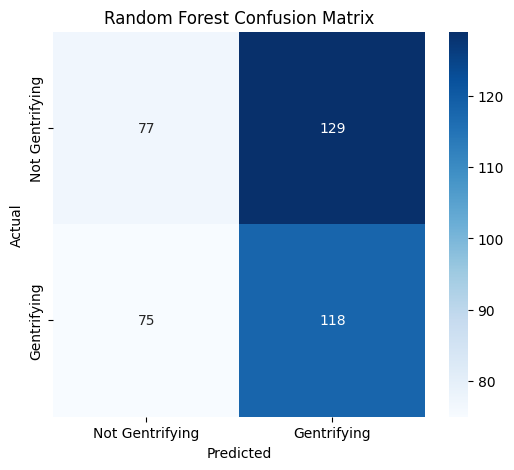

In [15]:
# ==============================
# STEP 5: CONFUSION MATRIX
# ==============================

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Gentrifying", "Gentrifying"],
    yticklabels=["Not Gentrifying", "Gentrifying"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [16]:
# ==============================
# STEP 6: FEATURE IMPORTANCE
# ==============================

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print("Top 20 Important Features:")
print(feature_importance.head(20))

Top 20 Important Features:
                            feature  importance
150     spatial_lag_housing_pre2012    0.016456
151  local_morans_I_housing_pre2012    0.013856
152      spatial_lag_income_pre2012    0.012439
153   local_morans_I_income_pre2012    0.010186
76   delta_2010_2011_DP3_HC01_VC121    0.008662
68    delta_2010_2011_DP3_HC01_VC91    0.008500
105  delta_2010_2011_DP4_HC01_VC122    0.008142
74   delta_2010_2011_DP3_HC01_VC112    0.008077
39   delta_2010_2011_DP2_HC01_VC188    0.007940
23   delta_2010_2011_DP2_HC01_VC119    0.007868
94    delta_2010_2011_DP4_HC01_VC74    0.007822
62    delta_2010_2011_DP3_HC01_VC69    0.007815
98    delta_2010_2011_DP4_HC01_VC92    0.007699
22    delta_2010_2011_DP2_HC01_VC99    0.007698
20    delta_2010_2011_DP2_HC01_VC87    0.007688
60    delta_2010_2011_DP3_HC01_VC60    0.007677
128   delta_2010_2011_DP5_HC01_VC15    0.007630
55    delta_2010_2011_DP3_HC01_VC42    0.007591
58    delta_2010_2011_DP3_HC01_VC54    0.007545
96    delta_2

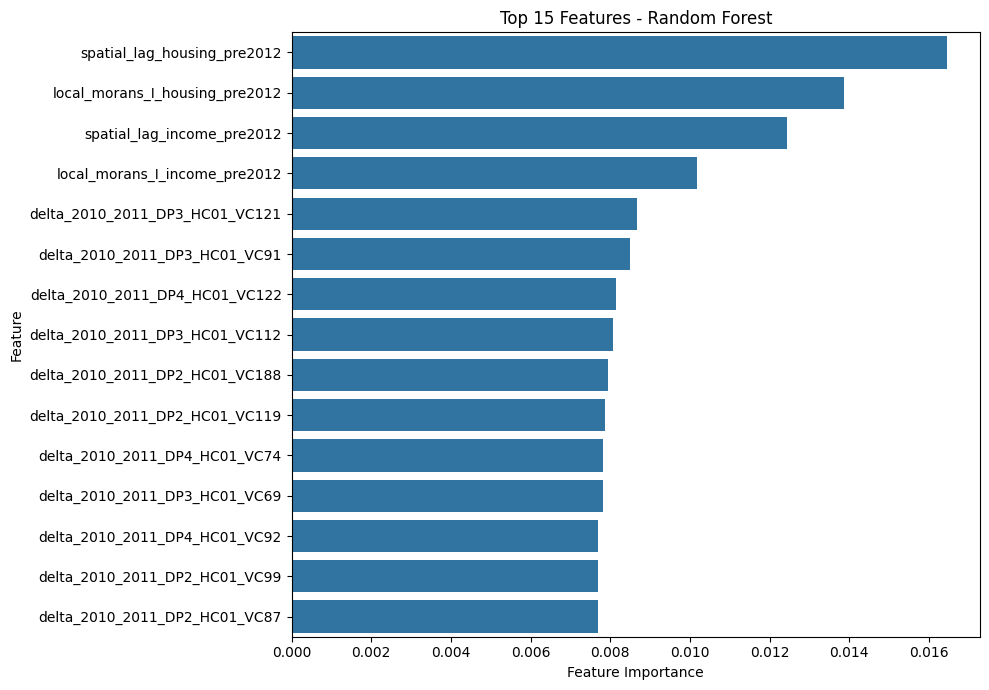

In [17]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [18]:
# ==============================
# STEP 7: SANITY CHECKS
# ==============================
from sklearn.metrics import roc_auc_score

print("1) Percent of tracts with label = 1, per split")
print(df.groupby("split")["housing_gentrification_label"].agg(["count", "mean"]).round(4))

print("\n2) Accuracy if we ALWAYS guess the majority class")
for name, labels in [("validation", y_val), ("test", y_test)]:
    print(f"   {name}: {labels.value_counts(normalize=True).max():.4f}")

print("\n3) Random Forest ROC-AUC on validation (0.5 = coin flip, 1.0 = perfect)")
val_scores = rf_model.predict_proba(X_val)[:, 1]
print("   ", round(roc_auc_score(y_val, val_scores), 4))

print("\n4) Share of test tracts whose county also appears in train")
train_counties = set(df.loc[train_mask, "county_fips"])
print("   ", round(df.loc[test_mask, "county_fips"].isin(train_counties).mean(), 4))

1) Percent of tracts with label = 1, per split
            count    mean
split                    
test          399  0.4837
train        7168  0.5202
validation    398  0.5276

2) Accuracy if we ALWAYS guess the majority class
   validation: 0.5276
   test: 0.5163

3) Random Forest ROC-AUC on validation (0.5 = coin flip, 1.0 = perfect)
    0.5937

4) Share of test tracts whose county also appears in train
    0.99


In [19]:
# ============================================================
# MODEL 2: LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train on training data
logistic_model.fit(X_train, y_train)

# Predictions on validation set
y_val_pred_lr = logistic_model.predict(X_val)
y_val_prob_lr = logistic_model.predict_proba(X_val)[:, 1]

# Calculate validation metrics
lr_accuracy = accuracy_score(y_val, y_val_pred_lr)
lr_precision = precision_score(y_val, y_val_pred_lr, zero_division=0)
lr_recall = recall_score(y_val, y_val_pred_lr, zero_division=0)
lr_f1 = f1_score(y_val, y_val_pred_lr, zero_division=0)
lr_auc = roc_auc_score(y_val, y_val_prob_lr)

print("===== LOGISTIC REGRESSION — VALIDATION RESULTS =====")
print(f"Accuracy :  {lr_accuracy:.4f}")
print(f"Precision:  {lr_precision:.4f}")
print(f"Recall   :  {lr_recall:.4f}")
print(f"F1 Score :  {lr_f1:.4f}")
print(f"ROC-AUC  :  {lr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_lr,
    target_names=["Not Gentrifying", "Gentrifying"],
    zero_division=0
))

===== LOGISTIC REGRESSION — VALIDATION RESULTS =====
Accuracy :  0.5101
Precision:  0.5301
Recall   :  0.6286
F1 Score :  0.5752
ROC-AUC  :  0.5226

Classification Report:
                 precision    recall  f1-score   support

Not Gentrifying       0.48      0.38      0.42       188
    Gentrifying       0.53      0.63      0.58       210

       accuracy                           0.51       398
      macro avg       0.50      0.50      0.50       398
   weighted avg       0.50      0.51      0.50       398



In [20]:
# ============================================================
# MODEL 3: XGBOOST
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

# Train on training data
xgb_model.fit(X_train, y_train)

# Predictions on validation set
y_val_pred_xgb = xgb_model.predict(X_val)
y_val_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

# Calculate validation metrics
xgb_accuracy = accuracy_score(y_val, y_val_pred_xgb)
xgb_precision = precision_score(y_val, y_val_pred_xgb, zero_division=0)
xgb_recall = recall_score(y_val, y_val_pred_xgb, zero_division=0)
xgb_f1 = f1_score(y_val, y_val_pred_xgb, zero_division=0)
xgb_auc = roc_auc_score(y_val, y_val_prob_xgb)

print("===== XGBOOST — VALIDATION RESULTS =====")
print(f"Accuracy :  {xgb_accuracy:.4f}")
print(f"Precision:  {xgb_precision:.4f}")
print(f"Recall   :  {xgb_recall:.4f}")
print(f"F1 Score :  {xgb_f1:.4f}")
print(f"ROC-AUC  :  {xgb_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_xgb,
    target_names=["Not Gentrifying", "Gentrifying"],
    zero_division=0
))

===== XGBOOST — VALIDATION RESULTS =====
Accuracy :  0.5302
Precision:  0.5535
Recall   :  0.5667
F1 Score :  0.5600
ROC-AUC  :  0.5302

Classification Report:
                 precision    recall  f1-score   support

Not Gentrifying       0.50      0.49      0.50       188
    Gentrifying       0.55      0.57      0.56       210

       accuracy                           0.53       398
      macro avg       0.53      0.53      0.53       398
   weighted avg       0.53      0.53      0.53       398



In [21]:
# ============================================================
# PROXIMITY FEATURE IMPORTANCE EXPERIMENT
# Remove proximity features and retrain XGBoost
# ============================================================

proximity_features = [
    "spatial_lag_housing_pre2012",
    "local_morans_I_housing_pre2012",
    "spatial_lag_income_pre2012",
    "local_morans_I_income_pre2012"
]

# Remove proximity features
X_train_no_proximity = X_train.drop(
    columns=proximity_features,
    errors="ignore"
)

X_val_no_proximity = X_val.drop(
    columns=proximity_features,
    errors="ignore"
)

print("Original number of features:", X_train.shape[1])
print("Features after removing proximity:", X_train_no_proximity.shape[1])

# Create XGBoost model
xgb_no_proximity = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

# Train without proximity features
xgb_no_proximity.fit(
    X_train_no_proximity,
    y_train
)

# Validation predictions
y_val_pred_no_proximity = xgb_no_proximity.predict(
    X_val_no_proximity
)

y_val_prob_no_proximity = xgb_no_proximity.predict_proba(
    X_val_no_proximity
)[:, 1]

# Metrics
no_prox_accuracy = accuracy_score(
    y_val,
    y_val_pred_no_proximity
)

no_prox_precision = precision_score(
    y_val,
    y_val_pred_no_proximity,
    zero_division=0
)

no_prox_recall = recall_score(
    y_val,
    y_val_pred_no_proximity,
    zero_division=0
)

no_prox_f1 = f1_score(
    y_val,
    y_val_pred_no_proximity,
    zero_division=0
)

no_prox_auc = roc_auc_score(
    y_val,
    y_val_prob_no_proximity
)

print("\n===== XGBOOST WITHOUT PROXIMITY FEATURES =====")
print(f"Accuracy :  {no_prox_accuracy:.4f}")
print(f"Precision:  {no_prox_precision:.4f}")
print(f"Recall   :  {no_prox_recall:.4f}")
print(f"F1 Score :  {no_prox_f1:.4f}")
print(f"ROC-AUC  :  {no_prox_auc:.4f}")

print("\n===== COMPARISON =====")
print(f"With proximity    ROC-AUC: {xgb_auc:.4f}")
print(f"Without proximity ROC-AUC: {no_prox_auc:.4f}")

Original number of features: 154
Features after removing proximity: 150

===== XGBOOST WITHOUT PROXIMITY FEATURES =====
Accuracy :  0.4874
Precision:  0.5143
Recall   :  0.5143
F1 Score :  0.5143
ROC-AUC  :  0.4717

===== COMPARISON =====
With proximity    ROC-AUC: 0.5302
Without proximity ROC-AUC: 0.4717


===== TOP 20 XGBOOST FEATURES =====


,Feature,Importance
150,spatial_lag_housing_pre2012,0.011447
151,local_morans_I_housing_pre2012,0.008953
37,delta_2010_2011_DP2_HC01_VC182,0.008737
93,delta_2010_2011_DP4_HC01_VC71,0.008498
136,delta_2010_2011_DP5_HC01_VC47,0.008054
152,spatial_lag_income_pre2012,0.007974
33,delta_2010_2011_DP2_HC01_VC166,0.007867
6,delta_2010_2011_DP2_HC01_VC27,0.007776
67,delta_2010_2011_DP3_HC01_VC88,0.007734
87,delta_2010_2011_DP4_HC01_VC43,0.007566


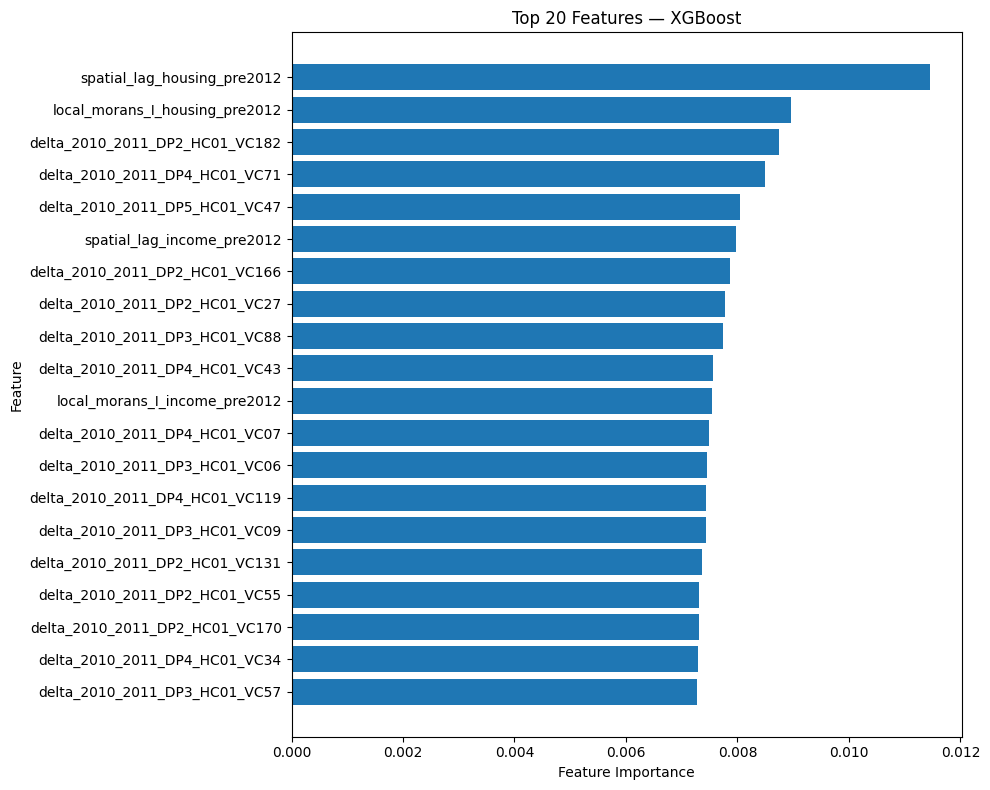

In [22]:
# ============================================================
# XGBOOST FEATURE IMPORTANCE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the XGBoost model
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
print("===== TOP 20 XGBOOST FEATURES =====")
display(feature_importance.head(20))

# Plot top 20 features
top_20 = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_20["Feature"],
    top_20["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features — XGBoost")

plt.tight_layout()
plt.show()

===== TOP 20 FEATURES — PERMUTATION IMPORTANCE =====


,Feature,Importance_Mean,Importance_Std
151,local_morans_I_housing_pre2012,0.023663,0.011212
152,spatial_lag_income_pre2012,0.011522,0.004211
98,delta_2010_2011_DP4_HC01_VC92,0.009172,0.002899
56,delta_2010_2011_DP3_HC01_VC45,0.008544,0.002978
36,delta_2010_2011_DP2_HC01_VC176,0.007333,0.002549
80,delta_2010_2011_DP4_HC01_VC16,0.007280,0.002784
68,delta_2010_2011_DP3_HC01_VC91,0.006829,0.002882
55,delta_2010_2011_DP3_HC01_VC42,0.005479,0.002083
67,delta_2010_2011_DP3_HC01_VC88,0.005061,0.004780
22,delta_2010_2011_DP2_HC01_VC99,0.004985,0.002561


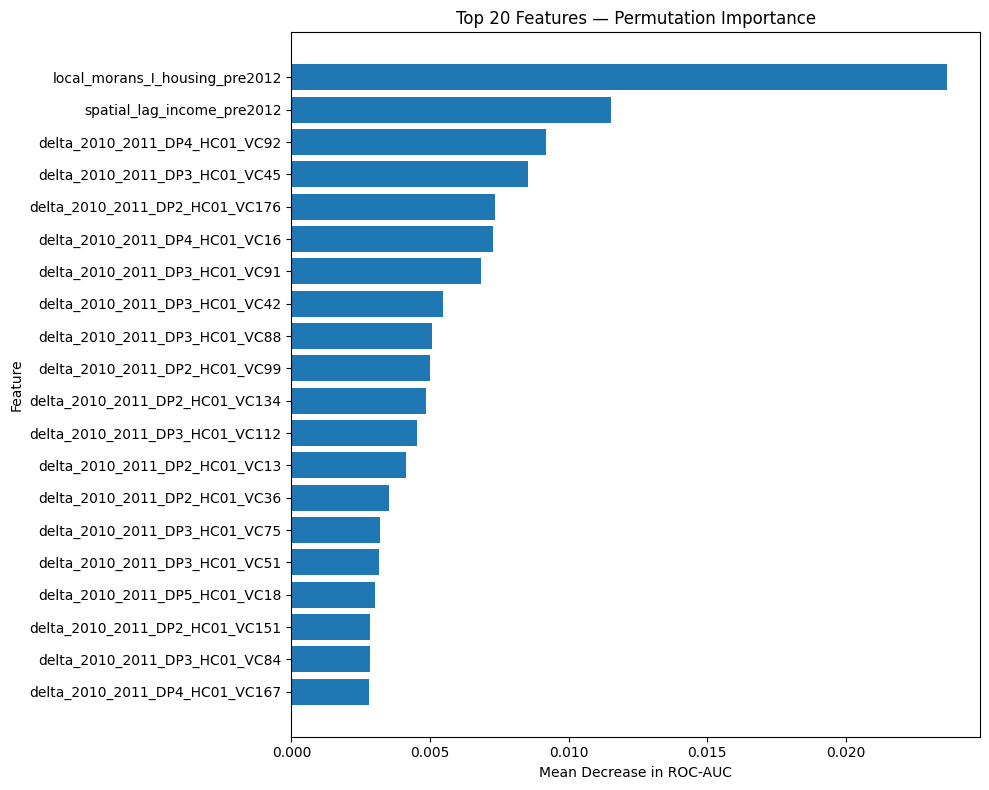

In [23]:
# ============================================================
# PERMUTATION IMPORTANCE — VALIDATION SET
# ============================================================

from sklearn.inspection import permutation_importance

# Calculate permutation importance using ROC-AUC
perm_result = permutation_importance(
    xgb_model,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create a table
permutation_importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
})

# Sort from most important to least important
permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

# Display top 20
print("===== TOP 20 FEATURES — PERMUTATION IMPORTANCE =====")

display(
    permutation_importance_df.head(20)
)

# Plot top 20
top_20_perm = permutation_importance_df.head(20).sort_values(
    by="Importance_Mean"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_20_perm["Feature"],
    top_20_perm["Importance_Mean"]
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.title("Top 20 Features — Permutation Importance")

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# XGBOOST HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

# Base XGBoost model
xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Parameters to search
param_grid = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.03, 0.05, 0.08, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_lambda": [1, 5, 10]
}

# Randomized search
xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=12,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train using ONLY the training set
print("Starting XGBoost hyperparameter tuning...")
print("This may take a few minutes.")

xgb_search.fit(X_train, y_train)

# Best parameters
print("\n===== BEST XGBOOST PARAMETERS =====")
print(xgb_search.best_params_)

print("\n===== BEST CROSS-VALIDATION ROC-AUC =====")
print(f"{xgb_search.best_score_:.4f}")

# Best model
tuned_xgb = xgb_search.best_estimator_

# Validation predictions
y_val_pred_tuned = tuned_xgb.predict(X_val)
y_val_prob_tuned = tuned_xgb.predict_proba(X_val)[:, 1]

# Validation metrics
tuned_accuracy = accuracy_score(
    y_val,
    y_val_pred_tuned
)

tuned_precision = precision_score(
    y_val,
    y_val_pred_tuned,
    zero_division=0
)

tuned_recall = recall_score(
    y_val,
    y_val_pred_tuned,
    zero_division=0
)

tuned_f1 = f1_score(
    y_val,
    y_val_pred_tuned,
    zero_division=0
)

tuned_auc = roc_auc_score(
    y_val,
    y_val_prob_tuned
)

print("\n===== TUNED XGBOOST — VALIDATION RESULTS =====")
print(f"Accuracy :  {tuned_accuracy:.4f}")
print(f"Precision:  {tuned_precision:.4f}")
print(f"Recall   :  {tuned_recall:.4f}")
print(f"F1 Score :  {tuned_f1:.4f}")
print(f"ROC-AUC  :  {tuned_auc:.4f}")

print("\n===== BASELINE VS TUNED =====")
print(f"Baseline XGBoost ROC-AUC : {xgb_auc:.4f}")
print(f"Tuned XGBoost ROC-AUC    : {tuned_auc:.4f}")

Starting XGBoost hyperparameter tuning...
This may take a few minutes.
Fitting 3 folds for each of 12 candidates, totalling 36 fits

===== BEST XGBOOST PARAMETERS =====
{'subsample': 0.9, 'reg_lambda': 5, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.08, 'colsample_bytree': 1.0}

===== BEST CROSS-VALIDATION ROC-AUC =====
0.5389

===== TUNED XGBOOST — VALIDATION RESULTS =====
Accuracy :  0.5276
Precision:  0.5514
Recall   :  0.5619
F1 Score :  0.5566
ROC-AUC  :  0.5195

===== BASELINE VS TUNED =====
Baseline XGBoost ROC-AUC : 0.5302
Tuned XGBoost ROC-AUC    : 0.5195


In [25]:
# ============================================================
# FINAL XGBOOST MODEL — TEST SET EVALUATION
# ============================================================

import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Combine training and validation data
# ------------------------------------------------------------

X_train_final = pd.concat(
    [X_train, X_val],
    axis=0
)

y_train_final = pd.concat(
    [y_train, y_val],
    axis=0
)

print("Final training samples:", X_train_final.shape[0])
print("Final test samples:", X_test.shape[0])
print("Number of features:", X_train_final.shape[1])

# ------------------------------------------------------------
# 2. Create final XGBoost model
# ------------------------------------------------------------

final_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

# ------------------------------------------------------------
# 3. Train final model
# ------------------------------------------------------------

print("\nTraining final XGBoost model...")

final_xgb.fit(
    X_train_final,
    y_train_final
)

print("Final model training complete!")

# ------------------------------------------------------------
# 4. Predict on untouched test set
# ------------------------------------------------------------

y_test_pred = final_xgb.predict(X_test)
y_test_prob = final_xgb.predict_proba(X_test)[:, 1]

# ------------------------------------------------------------
# 5. Calculate final test metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_auc = roc_auc_score(
    y_test,
    y_test_prob
)

# ------------------------------------------------------------
# 6. Display final results
# ------------------------------------------------------------

print("\n==========================================")
print("FINAL XGBOOST — TEST SET RESULTS")
print("==========================================")

print(f"Accuracy :  {test_accuracy:.4f}")
print(f"Precision:  {test_precision:.4f}")
print(f"Recall   :  {test_recall:.4f}")
print(f"F1 Score :  {test_f1:.4f}")
print(f"ROC-AUC  :  {test_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Not Gentrifying", "Gentrifying"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred
    )
)

Final training samples: 7566
Final test samples: 399
Number of features: 154

Training final XGBoost model...
Final model training complete!

FINAL XGBOOST — TEST SET RESULTS
Accuracy :  0.5188
Precision:  0.5023
Recall   :  0.5648
F1 Score :  0.5317
ROC-AUC  :  0.5176

Classification Report:
                 precision    recall  f1-score   support

Not Gentrifying       0.54      0.48      0.51       206
    Gentrifying       0.50      0.56      0.53       193

       accuracy                           0.52       399
      macro avg       0.52      0.52      0.52       399
   weighted avg       0.52      0.52      0.52       399


Confusion Matrix:
[[ 98 108]
 [ 84 109]]


In [26]:
# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Logistic Regression",
        "XGBoost",
        "Tuned XGBoost",
        "XGBoost Without Proximity"
    ],

    "Validation Accuracy": [
        0.4887,
        lr_accuracy,
        xgb_accuracy,
        tuned_accuracy,
        no_prox_accuracy
    ],

    "Validation Precision": [
        0.4777,
        lr_precision,
        xgb_precision,
        tuned_precision,
        no_prox_precision
    ],

    "Validation Recall": [
        0.6114,
        lr_recall,
        xgb_recall,
        tuned_recall,
        no_prox_recall
    ],

    "Validation F1": [
        0.0,
        lr_f1,
        xgb_f1,
        tuned_f1,
        no_prox_f1
    ],

    "Validation ROC-AUC": [
        0.5033,
        lr_auc,
        xgb_auc,
        tuned_auc,
        no_prox_auc
    ]
})

print("===== MODEL COMPARISON =====")

display(
    model_comparison.round(4)
)

print("\n===== FINAL TEST PERFORMANCE =====")

final_test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Test Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_auc
    ]
})

display(
    final_test_results.round(4)
)

===== MODEL COMPARISON =====


,Model,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC
0,Random Forest,0.4887,0.4777,0.6114,0.0000,0.5033
1,Logistic Regression,0.5101,0.5301,0.6286,0.5752,0.5226
2,XGBoost,0.5302,0.5535,0.5667,0.5600,0.5302
3,Tuned XGBoost,0.5276,0.5514,0.5619,0.5566,0.5195
4,XGBoost Without Proximity,0.4874,0.5143,0.5143,0.5143,0.4717



===== FINAL TEST PERFORMANCE =====


,Metric,Test Score
0,Accuracy,0.5188
1,Precision,0.5023
2,Recall,0.5648
3,F1 Score,0.5317
4,ROC-AUC,0.5176


In [29]:
# ============================================================
# PROJECT AUDIT — DATASET AND TARGET
# ============================================================

print("=" * 60)
print("DATASET AND TARGET AUDIT")
print("=" * 60)

# ------------------------------------------------------------
# 1. Dataset dimensions
# ------------------------------------------------------------

print("\n1. DATASET SHAPE")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# ------------------------------------------------------------
# 2. Target column
# ------------------------------------------------------------

target_column = "housing_gentrification_label"

print("\n2. TARGET COLUMN")
print("Target:", target_column)
print("Target exists:", target_column in df.columns)

# ------------------------------------------------------------
# 3. Target values
# ------------------------------------------------------------

print("\n3. TARGET VALUES")
print(df[target_column].value_counts(dropna=False).sort_index())

print("\nTarget proportions:")
print(
    df[target_column]
    .value_counts(normalize=True)
    .sort_index()
    .round(4)
)

# ------------------------------------------------------------
# 4. Missing values
# ------------------------------------------------------------

print("\n4. MISSING VALUES")

total_missing = df.isnull().sum().sum()

print("Total missing values in entire dataset:", total_missing)

# ------------------------------------------------------------
# 5. Duplicate rows
# ------------------------------------------------------------

print("\n5. DUPLICATES")

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

# ------------------------------------------------------------
# 6. Data types
# ------------------------------------------------------------

print("\n6. DATA TYPES")

print(df.dtypes.value_counts())

# ------------------------------------------------------------
# 7. Number of unique values in target
# ------------------------------------------------------------

print("\n7. UNIQUE TARGET VALUES")

print(df[target_column].unique())

# ------------------------------------------------------------
# 8. Target missing values
# ------------------------------------------------------------

print("\n8. MISSING TARGET VALUES")

print(df[target_column].isnull().sum())

# ------------------------------------------------------------
# 9. Current ML feature count
# ------------------------------------------------------------

print("\n9. ML FEATURE COUNT")

print("X shape:", X.shape)
print("Number of ML features:", X.shape[1])

# ------------------------------------------------------------
# 10. Train / validation / test sizes
# ------------------------------------------------------------

print("\n10. DATA SPLIT")

print("Training:", X_train.shape[0])
print("Validation:", X_val.shape[0])
print("Test:", X_test.shape[0])

print(
    "Total:",
    X_train.shape[0] +
    X_val.shape[0] +
    X_test.shape[0]
)

# ------------------------------------------------------------
# 11. Feature missing values after preprocessing
# ------------------------------------------------------------

print("\n11. MISSING VALUES IN ML FEATURES")

print("Training missing:", X_train.isnull().sum().sum())
print("Validation missing:", X_val.isnull().sum().sum())
print("Test missing:", X_test.isnull().sum().sum())

print("\n" + "=" * 60)
print("AUDIT COMPLETE")
print("=" * 60)

DATASET AND TARGET AUDIT

1. DATASET SHAPE
Rows: 7965
Columns: 167

2. TARGET COLUMN
Target: housing_gentrification_label
Target exists: True

3. TARGET VALUES
housing_gentrification_label
0    3833
1    4132
Name: count, dtype: int64

Target proportions:
housing_gentrification_label
0    0.4812
1    0.5188
Name: proportion, dtype: float64

4. MISSING VALUES
Total missing values in entire dataset: 553

5. DUPLICATES
Duplicate rows: 0

6. DATA TYPES
float64    160
int64        6
object       1
Name: count, dtype: int64

7. UNIQUE TARGET VALUES
[1 0]

8. MISSING TARGET VALUES
0

9. ML FEATURE COUNT
X shape: (7965, 154)
Number of ML features: 154

10. DATA SPLIT
Training: 7168
Validation: 398
Test: 399
Total: 7965

11. MISSING VALUES IN ML FEATURES
Training missing: 0
Validation missing: 0
Test missing: 0

AUDIT COMPLETE


In [30]:
# ============================================================
# PROJECT AUDIT — MISSING VALUES
# ============================================================

print("=" * 60)
print("MISSING VALUE AUDIT")
print("=" * 60)

missing_counts = df.isnull().sum()

missing_columns = (
    missing_counts[missing_counts > 0]
    .sort_values(ascending=False)
)

print("\nColumns containing missing values:")
print(missing_columns)

print("\nTotal columns containing missing values:",
      len(missing_columns))

print("\nTotal missing values:",
      missing_columns.sum())

print("\nAre any ML features missing values?")

ml_missing = X.isnull().sum()
ml_missing = ml_missing[ml_missing > 0]

if len(ml_missing) == 0:
    print("YES/NO CHECK: NO ML FEATURES HAVE MISSING VALUES")
else:
    print("WARNING: Some ML features contain missing values:")
    print(ml_missing)

print("\n" + "=" * 60)
print("MISSING VALUE AUDIT COMPLETE")
print("=" * 60)

MISSING VALUE AUDIT

Columns containing missing values:
pre_housing_change    546
pre_income_change       7
dtype: int64

Total columns containing missing values: 2

Total missing values: 553

Are any ML features missing values?
YES/NO CHECK: NO ML FEATURES HAVE MISSING VALUES

MISSING VALUE AUDIT COMPLETE


In [31]:
# ============================================================
# PROJECT AUDIT — DATA LEAKAGE CHECK
# ============================================================

print("=" * 60)
print("DATA LEAKAGE AUDIT")
print("=" * 60)

# ------------------------------------------------------------
# 1. TARGET MUST NOT BE IN X
# ------------------------------------------------------------

target_column = "housing_gentrification_label"

print("\n1. TARGET COLUMN CHECK")
print("Target:", target_column)
print("Target present in X:",
      target_column in X.columns)

# ------------------------------------------------------------
# 2. KNOWN LEAKAGE COLUMNS
# ------------------------------------------------------------

known_leakage_columns = [
    "housing_cost_response",
    "housing_gentrification_score",
    "housing_gentrification_label",
    "income_hellinger_response",
    "income_gentrification_score",
    "income_gentrification_label"
]

print("\n2. KNOWN LEAKAGE COLUMNS")

leakage_present = []

for col in known_leakage_columns:
    if col in X.columns:
        leakage_present.append(col)

if len(leakage_present) == 0:
    print("No known leakage columns are present in X.")
else:
    print("WARNING — LEAKAGE COLUMNS FOUND:")
    for col in leakage_present:
        print("  ", col)

# ------------------------------------------------------------
# 3. PROXIMITY FEATURES
# ------------------------------------------------------------

proximity_features = [
    "spatial_lag_housing_pre2012",
    "local_morans_I_housing_pre2012",
    "spatial_lag_income_pre2012",
    "local_morans_I_income_pre2012"
]

print("\n3. PROXIMITY FEATURES")

for col in proximity_features:
    print(
        col,
        "->",
        "PRESENT" if col in X.columns else "MISSING"
    )

# ------------------------------------------------------------
# 4. POSSIBLE ID / GEOGRAPHIC IDENTIFIERS
# ------------------------------------------------------------

possible_identifier_terms = [
    "id",
    "geoid",
    "tract",
    "county",
    "state",
    "fips"
]

possible_identifiers = []

for col in X.columns:
    col_lower = col.lower()

    if any(term in col_lower for term in possible_identifier_terms):
        possible_identifiers.append(col)

print("\n4. POSSIBLE IDENTIFIER / GEOGRAPHIC COLUMNS IN X")

if len(possible_identifiers) == 0:
    print("None found.")
else:
    for col in possible_identifiers:
        print("  ", col)

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

print("\n5. LEAKAGE AUDIT SUMMARY")

if target_column not in X.columns:
    print("✓ Target is not included in ML features.")
else:
    print("✗ Target IS included in ML features.")

if len(leakage_present) == 0:
    print("✓ No known target-derived leakage columns found.")
else:
    print("✗ Known leakage columns were found.")

print("\nNumber of ML features:", X.shape[1])

print("\n" + "=" * 60)
print("LEAKAGE AUDIT COMPLETE")
print("=" * 60)

DATA LEAKAGE AUDIT

1. TARGET COLUMN CHECK
Target: housing_gentrification_label
Target present in X: False

2. KNOWN LEAKAGE COLUMNS
No known leakage columns are present in X.

3. PROXIMITY FEATURES
spatial_lag_housing_pre2012 -> PRESENT
local_morans_I_housing_pre2012 -> PRESENT
spatial_lag_income_pre2012 -> PRESENT
local_morans_I_income_pre2012 -> PRESENT

4. POSSIBLE IDENTIFIER / GEOGRAPHIC COLUMNS IN X
None found.

5. LEAKAGE AUDIT SUMMARY
✓ Target is not included in ML features.
✓ No known target-derived leakage columns found.

Number of ML features: 154

LEAKAGE AUDIT COMPLETE


In [32]:
# ============================================================
# PROJECT AUDIT — TEMPORAL / EARLY WARNING CHECK
# ============================================================

print("=" * 60)
print("TEMPORAL / EARLY WARNING AUDIT")
print("=" * 60)

print("\n1. ALL ML FEATURE NAMES")
print("-" * 60)

for i, col in enumerate(X.columns, start=1):
    print(f"{i:3}. {col}")

print("\n2. FEATURES CONTAINING YEAR INFORMATION")
print("-" * 60)

year_terms = [
    "2010",
    "2011",
    "2012",
    "2013",
    "2014",
    "2015",
    "2016",
    "2017",
    "2018",
    "2019",
    "2020"
]

for col in X.columns:
    found_years = [year for year in year_terms if year in col]

    if found_years:
        print(f"{col} -> {', '.join(found_years)}")

print("\n3. FEATURES MARKED AS PRE-EVENT / PRE-2012")
print("-" * 60)

pre_features = [
    col for col in X.columns
    if "pre" in col.lower()
]

print("Number of features containing 'pre':", len(pre_features))

for col in pre_features:
    print(col)

print("\n4. DELTA FEATURES")
print("-" * 60)

delta_features = [
    col for col in X.columns
    if "delta" in col.lower()
]

print("Number of delta features:", len(delta_features))

for col in delta_features:
    print(col)

print("\n" + "=" * 60)
print("TEMPORAL / EARLY WARNING AUDIT COMPLETE")
print("=" * 60)

TEMPORAL / EARLY WARNING AUDIT

1. ALL ML FEATURE NAMES
------------------------------------------------------------
  1. delta_2010_2011_DP2_HC01_VC03
  2. delta_2010_2011_DP2_HC01_VC07
  3. delta_2010_2011_DP2_HC01_VC10
  4. delta_2010_2011_DP2_HC01_VC13
  5. delta_2010_2011_DP2_HC01_VC17
  6. delta_2010_2011_DP2_HC01_VC21
  7. delta_2010_2011_DP2_HC01_VC27
  8. delta_2010_2011_DP2_HC01_VC30
  9. delta_2010_2011_DP2_HC01_VC36
 10. delta_2010_2011_DP2_HC01_VC39
 11. delta_2010_2011_DP2_HC01_VC43
 12. delta_2010_2011_DP2_HC01_VC46
 13. delta_2010_2011_DP2_HC01_VC52
 14. delta_2010_2011_DP2_HC01_VC55
 15. delta_2010_2011_DP2_HC01_VC61
 16. delta_2010_2011_DP2_HC01_VC65
 17. delta_2010_2011_DP2_HC01_VC69
 18. delta_2010_2011_DP2_HC01_VC75
 19. delta_2010_2011_DP2_HC01_VC78
 20. delta_2010_2011_DP2_HC01_VC84
 21. delta_2010_2011_DP2_HC01_VC87
 22. delta_2010_2011_DP2_HC01_VC90
 23. delta_2010_2011_DP2_HC01_VC99
 24. delta_2010_2011_DP2_HC01_VC119
 25. delta_2010_2011_DP2_HC01_VC122
 26. d

In [33]:
# ============================================================
# PROJECT AUDIT — TARGET CONSTRUCTION
# ============================================================

print("=" * 60)
print("TARGET CONSTRUCTION AUDIT")
print("=" * 60)

print("\nTARGET COLUMN:")
print("housing_gentrification_label")

print("\nPOSSIBLE TARGET / SCORE / RESPONSE COLUMNS IN DATASET:")
print("-" * 60)

target_related_terms = [
    "gentrification",
    "gentrify",
    "response",
    "score",
    "label"
]

target_related_columns = []

for col in df.columns:
    col_lower = col.lower()

    if any(term in col_lower for term in target_related_terms):
        target_related_columns.append(col)

for col in target_related_columns:
    print(col)

print("\nTOTAL TARGET-RELATED COLUMNS:",
      len(target_related_columns))

print("\nTARGET-RELATED COLUMNS CURRENTLY USED BY MODEL:")
print("-" * 60)

for col in target_related_columns:
    if col in X.columns:
        print("USED:", col)

print("\nTARGET-RELATED COLUMNS EXCLUDED FROM MODEL:")
print("-" * 60)

for col in target_related_columns:
    if col not in X.columns:
        print("EXCLUDED:", col)

print("\n" + "=" * 60)
print("TARGET CONSTRUCTION AUDIT COMPLETE")
print("=" * 60)

TARGET CONSTRUCTION AUDIT

TARGET COLUMN:
housing_gentrification_label

POSSIBLE TARGET / SCORE / RESPONSE COLUMNS IN DATASET:
------------------------------------------------------------
housing_cost_response
housing_gentrification_score
housing_gentrification_label
income_hellinger_response
income_gentrification_score
income_gentrification_label

TOTAL TARGET-RELATED COLUMNS: 6

TARGET-RELATED COLUMNS CURRENTLY USED BY MODEL:
------------------------------------------------------------

TARGET-RELATED COLUMNS EXCLUDED FROM MODEL:
------------------------------------------------------------
EXCLUDED: housing_cost_response
EXCLUDED: housing_gentrification_score
EXCLUDED: housing_gentrification_label
EXCLUDED: income_hellinger_response
EXCLUDED: income_gentrification_score
EXCLUDED: income_gentrification_label

TARGET CONSTRUCTION AUDIT COMPLETE


In [34]:
# ============================================================
# PROJECT AUDIT — TARGET TEMPORAL RELATIONSHIP
# ============================================================

print("=" * 60)
print("TARGET TEMPORAL RELATIONSHIP AUDIT")
print("=" * 60)

print("\nTARGET-RELATED COLUMN DETAILS")
print("-" * 60)

target_related_columns = [
    "housing_cost_response",
    "housing_gentrification_score",
    "housing_gentrification_label",
    "income_hellinger_response",
    "income_gentrification_score",
    "income_gentrification_label"
]

for col in target_related_columns:
    if col in df.columns:
        print(f"\n{col}")
        print("  dtype:", df[col].dtype)
        print("  non-null:", df[col].notna().sum())
        print("  unique values:", df[col].nunique())

        if df[col].nunique() <= 10:
            print("  values:", sorted(df[col].dropna().unique().tolist()))

print("\n\nALL COLUMNS CONTAINING YEAR INFORMATION")
print("-" * 60)

for col in df.columns:
    found_years = [
        year for year in [
            "2000", "2001", "2002", "2003", "2004", "2005",
            "2006", "2007", "2008", "2009", "2010", "2011",
            "2012", "2013", "2014", "2015", "2016", "2017",
            "2018", "2019", "2020"
        ]
        if year in col
    ]

    if found_years:
        print(f"{col} -> {', '.join(found_years)}")

print("\n" + "=" * 60)
print("TARGET TEMPORAL RELATIONSHIP AUDIT COMPLETE")
print("=" * 60)

TARGET TEMPORAL RELATIONSHIP AUDIT

TARGET-RELATED COLUMN DETAILS
------------------------------------------------------------

housing_cost_response
  dtype: float64
  non-null: 7965
  unique values: 1104

housing_gentrification_score
  dtype: float64
  non-null: 7965
  unique values: 1104

housing_gentrification_label
  dtype: int64
  non-null: 7965
  unique values: 2
  values: [0, 1]

income_hellinger_response
  dtype: float64
  non-null: 7965
  unique values: 7724

income_gentrification_score
  dtype: float64
  non-null: 7965
  unique values: 7720

income_gentrification_label
  dtype: int64
  non-null: 7965
  unique values: 2
  values: [0, 1]


ALL COLUMNS CONTAINING YEAR INFORMATION
------------------------------------------------------------
delta_2010_2011_DP2_HC01_VC03 -> 2010, 2011
delta_2010_2011_DP2_HC01_VC07 -> 2010, 2011
delta_2010_2011_DP2_HC01_VC10 -> 2010, 2011
delta_2010_2011_DP2_HC01_VC13 -> 2010, 2011
delta_2010_2011_DP2_HC01_VC17 -> 2010, 2011
delta_2010_2011_DP2_HC

In [35]:
# ============================================================
# TARGET VALUE / SCORE CHECK
# ============================================================

target_columns = [
    "housing_cost_response",
    "housing_gentrification_score",
    "housing_gentrification_label",
    "income_hellinger_response",
    "income_gentrification_score",
    "income_gentrification_label"
]

print("=" * 60)
print("TARGET-RELATED COLUMN VALUE CHECK")
print("=" * 60)

for col in target_columns:
    print("\n" + col)
    print("-" * 40)
    print(df[col].describe())
    print("First 10 values:")
    print(df[col].head(10).tolist())

print("\n" + "=" * 60)
print("CHECK COMPLETE")
print("=" * 60)

TARGET-RELATED COLUMN VALUE CHECK

housing_cost_response
----------------------------------------
count    7965.000000
mean       -2.407156
std       202.150071
min     -1299.000000
25%       -98.000000
50%         8.000000
75%       104.000000
max      1346.000000
Name: housing_cost_response, dtype: float64
First 10 values:
[823.0, 378.0, -317.0, 57.0, 150.0, 25.0, 453.0, 0.0, -137.0, 282.0]

housing_gentrification_score
----------------------------------------
count    7965.000000
mean       49.020523
std         7.642725
min         0.000000
25%        45.406427
50%        49.413989
75%        53.043478
max       100.000000
Name: housing_gentrification_score, dtype: float64
First 10 values:
[80.22684310018903, 63.40264650283554, 37.12665406427221, 51.26654064272212, 54.78260869565217, 50.05671077504726, 66.23818525519849, 49.11153119092628, 43.93194706994329, 59.77315689981096]

housing_gentrification_label
----------------------------------------
count    7965.000000
mean        0.

In [36]:
# Check every column related to target construction

target_related = [
    col for col in df.columns
    if "gentrification" in col.lower()
    or "housing_cost" in col.lower()
    or "income_hellinger" in col.lower()
]

print("Target-related columns:")
for col in target_related:
    print("-", col)

Target-related columns:
- housing_cost_response
- housing_gentrification_score
- housing_gentrification_label
- income_hellinger_response
- income_gentrification_score
- income_gentrification_label


In [37]:
print(df[[
    "housing_cost_response",
    "housing_gentrification_score",
    "housing_gentrification_label",
    "income_hellinger_response",
    "income_gentrification_score",
    "income_gentrification_label"
]].head(10))

   housing_cost_response  housing_gentrification_score  \
0                  823.0                     80.226843   
1                  378.0                     63.402647   
2                 -317.0                     37.126654   
3                   57.0                     51.266541   
4                  150.0                     54.782609   
5                   25.0                     50.056711   
6                  453.0                     66.238185   
7                    0.0                     49.111531   
8                 -137.0                     43.931947   
9                  282.0                     59.773157   

   housing_gentrification_label  income_hellinger_response  \
0                             1                   0.019452   
1                             1                  -0.006122   
2                             0                   0.025489   
3                             1                   0.050356   
4                             1                   0

In [38]:
# Check whether the dataset contains year/time information
# related to the housing gentrification target.

housing_cols = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "housing",
        "2010",
        "2011",
        "2012",
        "2013",
        "2014",
        "2015",
        "2016"
    ])
]

print("Housing / year-related columns:")
for col in housing_cols:
    print(col)

Housing / year-related columns:
delta_2010_2011_DP2_HC01_VC03
delta_2010_2011_DP2_HC01_VC07
delta_2010_2011_DP2_HC01_VC10
delta_2010_2011_DP2_HC01_VC13
delta_2010_2011_DP2_HC01_VC17
delta_2010_2011_DP2_HC01_VC21
delta_2010_2011_DP2_HC01_VC27
delta_2010_2011_DP2_HC01_VC30
delta_2010_2011_DP2_HC01_VC36
delta_2010_2011_DP2_HC01_VC39
delta_2010_2011_DP2_HC01_VC43
delta_2010_2011_DP2_HC01_VC46
delta_2010_2011_DP2_HC01_VC52
delta_2010_2011_DP2_HC01_VC55
delta_2010_2011_DP2_HC01_VC61
delta_2010_2011_DP2_HC01_VC65
delta_2010_2011_DP2_HC01_VC69
delta_2010_2011_DP2_HC01_VC75
delta_2010_2011_DP2_HC01_VC78
delta_2010_2011_DP2_HC01_VC84
delta_2010_2011_DP2_HC01_VC87
delta_2010_2011_DP2_HC01_VC90
delta_2010_2011_DP2_HC01_VC99
delta_2010_2011_DP2_HC01_VC119
delta_2010_2011_DP2_HC01_VC122
delta_2010_2011_DP2_HC01_VC128
delta_2010_2011_DP2_HC01_VC131
delta_2010_2011_DP2_HC01_VC134
delta_2010_2011_DP2_HC01_VC140
delta_2010_2011_DP2_HC01_VC147
delta_2010_2011_DP2_HC01_VC151
delta_2010_2011_DP2_HC01_VC157

In [39]:
print("Rows and columns around the target:")
print(df[[
    "pre_housing_change",
    "housing_cost_response",
    "housing_gentrification_score",
    "housing_gentrification_label"
]].head(20).to_string())

print("\nColumn names containing 'housing':")
for col in df.columns:
    if "housing" in col.lower():
        print(col)

Rows and columns around the target:
    pre_housing_change  housing_cost_response  housing_gentrification_score  housing_gentrification_label
0                307.0                  823.0                     80.226843                             1
1                207.0                  378.0                     63.402647                             1
2                 68.0                 -317.0                     37.126654                             0
3                  NaN                   57.0                     51.266541                             1
4                -49.0                  150.0                     54.782609                             1
5                250.0                   25.0                     50.056711                             1
6                  NaN                  453.0                     66.238185                             1
7                  NaN                    0.0                     49.111531                             0
8         

In [40]:
# Verify how housing_gentrification_label was generated

calculated_label = (
    df["housing_gentrification_score"] >= 50
).astype(int)

matches = (
    calculated_label == df["housing_gentrification_label"]
).sum()

total = len(df)

print("Total rows:", total)
print("Matching labels:", matches)
print("Mismatching labels:", total - matches)
print("Match percentage:", matches / total * 100)

print("\nRows where the calculated label differs from the dataset label:")
print(
    df.loc[
        calculated_label != df["housing_gentrification_label"],
        [
            "housing_gentrification_score",
            "housing_gentrification_label"
        ]
    ].head(20)
)

Total rows: 7965
Matching labels: 7450
Mismatching labels: 515
Match percentage: 93.53421217827997

Rows where the calculated label differs from the dataset label:
     housing_gentrification_score  housing_gentrification_label
35                      49.376181                             1
40                      49.300567                             1
41                      49.905482                             1
49                      49.565217                             1
54                      49.943289                             1
68                      49.678639                             1
93                      49.603025                             1
96                      49.376181                             1
109                     49.224953                             1
116                     49.451796                             1
174                     49.905482                             1
184                     49.867675                             1
192 

In [41]:
# Examine housing score values around the 50-point boundary

boundary_rows = df[
    (df["housing_gentrification_score"] >= 47) &
    (df["housing_gentrification_score"] <= 53)
][[
    "pre_housing_change",
    "housing_cost_response",
    "housing_gentrification_score",
    "housing_gentrification_label"
]].sort_values("housing_gentrification_score")

print(boundary_rows.to_string(index=True))

      pre_housing_change  housing_cost_response  housing_gentrification_score  housing_gentrification_label
7800               113.0                  -55.0                     47.032136                             0
2968               221.0                  -55.0                     47.032136                             0
5734                47.0                  -55.0                     47.032136                             0
1591                51.0                  -55.0                     47.032136                             0
5574                 NaN                  -55.0                     47.032136                             0
3270               -28.0                  -55.0                     47.032136                             0
4521                39.0                  -55.0                     47.032136                             0
7352                37.0                  -55.0                     47.032136                             0
3140              -111.0    

In [42]:
# Check how the label behaves at different score thresholds

for threshold in [45, 46, 47, 48, 49, 49.0, 49.2, 49.3, 49.4, 49.5, 49.6, 49.7, 49.8, 49.9, 50]:
    predicted = (df["housing_gentrification_score"] >= threshold).astype(int)
    accuracy = (predicted == df["housing_gentrification_label"]).mean() * 100
    print(f"Threshold {threshold:5.1f} -> {accuracy:.2f}% match")

Threshold  45.0 -> 75.13% match
Threshold  46.0 -> 79.71% match
Threshold  47.0 -> 85.15% match
Threshold  48.0 -> 91.41% match
Threshold  49.0 -> 99.15% match
Threshold  49.0 -> 99.15% match
Threshold  49.2 -> 99.38% match
Threshold  49.3 -> 98.93% match
Threshold  49.4 -> 98.19% match
Threshold  49.5 -> 97.43% match
Threshold  49.6 -> 96.95% match
Threshold  49.7 -> 95.98% match
Threshold  49.8 -> 95.04% match
Threshold  49.9 -> 94.53% match
Threshold  50.0 -> 93.53% match


In [43]:
# Find cells/variables related to target creation

print("Looking for target-related variables in the current notebook...")
print()

for name in [
    "housing_cost_response",
    "housing_gentrification_score",
    "housing_gentrification_label",
    "pre_housing_change",
    "income_hellinger_response",
    "income_gentrification_score",
    "income_gentrification_label"
]:
    print(name, "->", name in globals())

Looking for target-related variables in the current notebook...

housing_cost_response -> False
housing_gentrification_score -> False
housing_gentrification_label -> False
pre_housing_change -> False
income_hellinger_response -> False
income_gentrification_score -> False
income_gentrification_label -> False


In [44]:
print("Target-related columns and their statistics:\n")

target_cols = [
    "pre_housing_change",
    "housing_cost_response",
    "housing_gentrification_score",
    "housing_gentrification_label",
    "income_hellinger_response",
    "income_gentrification_score",
    "income_gentrification_label"
]

for col in target_cols:
    print(f"\n===== {col} =====")
    print("dtype:", df[col].dtype)
    print("missing:", df[col].isna().sum())
    print("unique:", df[col].nunique())
    print("min:", df[col].min())
    print("max:", df[col].max())

Target-related columns and their statistics:


===== pre_housing_change =====
dtype: float64
missing: 546
unique: 1050
min: -2320.0
max: 2294.0

===== housing_cost_response =====
dtype: float64
missing: 0
unique: 1104
min: -1299.0
max: 1346.0

===== housing_gentrification_score =====
dtype: float64
missing: 0
unique: 1104
min: 0.0
max: 100.0

===== housing_gentrification_label =====
dtype: int64
missing: 0
unique: 2
min: 0
max: 1

===== income_hellinger_response =====
dtype: float64
missing: 0
unique: 7724
min: -0.5155619005179519
max: 0.3138150848444118

===== income_gentrification_score =====
dtype: float64
missing: 0
unique: 7720
min: 24.221904974102404
max: 65.69075424222059

===== income_gentrification_label =====
dtype: int64
missing: 0
unique: 2
min: 0
max: 1


In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Train Random Forest again
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Validation predictions
y_val_pred_rf = rf_model.predict(X_val)
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

# Calculate validation metrics
rf_accuracy_val = accuracy_score(y_val, y_val_pred_rf)
rf_precision_val = precision_score(y_val, y_val_pred_rf, zero_division=0)
rf_recall_val = recall_score(y_val, y_val_pred_rf, zero_division=0)
rf_f1_val = f1_score(y_val, y_val_pred_rf, zero_division=0)
rf_auc_val = roc_auc_score(y_val, y_val_prob_rf)

print("Random Forest - Validation Results")
print("-----------------------------------")
print(f"Accuracy : {rf_accuracy_val:.4f}")
print(f"Precision: {rf_precision_val:.4f}")
print(f"Recall   : {rf_recall_val:.4f}")
print(f"F1 Score : {rf_f1_val:.4f}")
print(f"ROC-AUC  : {rf_auc_val:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_rf,
    target_names=["Not Gentrifying", "Gentrifying"],
    zero_division=0
))

Random Forest - Validation Results
-----------------------------------
Accuracy : 0.5754
Precision: 0.5844
Recall   : 0.6762
F1 Score : 0.6269
ROC-AUC  : 0.5937

Classification Report:
                 precision    recall  f1-score   support

Not Gentrifying       0.56      0.46      0.51       188
    Gentrifying       0.58      0.68      0.63       210

       accuracy                           0.58       398
      macro avg       0.57      0.57      0.57       398
   weighted avg       0.57      0.58      0.57       398



In [47]:
import pandas as pd

# Final validation results from all experiments

model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Logistic Regression",
        "XGBoost",
        "Tuned XGBoost",
        "XGBoost Without Proximity"
    ],
    "Accuracy": [
        0.5754,
        0.5101,
        0.5302,
        0.5276,
        0.4874
    ],
    "Precision": [
        0.5844,
        0.5301,
        0.5535,
        0.5514,
        0.5143
    ],
    "Recall": [
        0.6762,
        0.6286,
        0.5667,
        0.5619,
        0.5143
    ],
    "F1": [
        0.6269,
        0.5752,
        0.5600,
        0.5566,
        0.5143
    ],
    "ROC-AUC": [
        0.5937,
        0.5226,
        0.5302,
        0.5195,
        0.4717
    ]
})

print("FINAL MODEL COMPARISON — VALIDATION SET")
display(model_comparison.round(4))

FINAL MODEL COMPARISON — VALIDATION SET


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.5754,0.5844,0.6762,0.6269,0.5937
1,Logistic Regression,0.5101,0.5301,0.6286,0.5752,0.5226
2,XGBoost,0.5302,0.5535,0.5667,0.5600,0.5302
3,Tuned XGBoost,0.5276,0.5514,0.5619,0.5566,0.5195
4,XGBoost Without Proximity,0.4874,0.5143,0.5143,0.5143,0.4717


In [48]:
# Final Random Forest Evaluation on the Untouched Test Set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Test predictions
y_test_pred_rf = rf_model.predict(X_test)
y_test_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Test metrics
rf_test_accuracy = accuracy_score(y_test, y_test_pred_rf)
rf_test_precision = precision_score(y_test, y_test_pred_rf, zero_division=0)
rf_test_recall = recall_score(y_test, y_test_pred_rf, zero_division=0)
rf_test_f1 = f1_score(y_test, y_test_pred_rf, zero_division=0)
rf_test_auc = roc_auc_score(y_test, y_test_prob_rf)

print("FINAL RANDOM FOREST — TEST SET")
print("--------------------------------")
print(f"Accuracy : {rf_test_accuracy:.4f}")
print(f"Precision: {rf_test_precision:.4f}")
print(f"Recall   : {rf_test_recall:.4f}")
print(f"F1 Score : {rf_test_f1:.4f}")
print(f"ROC-AUC  : {rf_test_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_rf,
    target_names=["Not Gentrifying", "Gentrifying"],
    zero_division=0
))

FINAL RANDOM FOREST — TEST SET
--------------------------------
Accuracy : 0.4887
Precision: 0.4777
Recall   : 0.6114
F1 Score : 0.5364
ROC-AUC  : 0.5033

Confusion Matrix:
[[ 77 129]
 [ 75 118]]

Classification Report:
                 precision    recall  f1-score   support

Not Gentrifying       0.51      0.37      0.43       206
    Gentrifying       0.48      0.61      0.54       193

       accuracy                           0.49       399
      macro avg       0.49      0.49      0.48       399
   weighted avg       0.49      0.49      0.48       399



In [49]:
# Random Forest Ablation Study:
# Compare Random Forest WITH and WITHOUT proximity features

proximity_features = [
    "spatial_lag_housing_pre2012",
    "local_morans_I_housing_pre2012",
    "spatial_lag_income_pre2012",
    "local_morans_I_income_pre2012"
]

# Remove proximity features
X_train_no_prox = X_train.drop(columns=proximity_features)
X_val_no_prox = X_val.drop(columns=proximity_features)
X_test_no_prox = X_test.drop(columns=proximity_features)

print("Original number of features:", X_train.shape[1])
print("Features without proximity:", X_train_no_prox.shape[1])

# Train Random Forest without proximity features
rf_no_prox = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_no_prox.fit(X_train_no_prox, y_train)

# Validation predictions
y_val_pred_rf_no_prox = rf_no_prox.predict(X_val_no_prox)
y_val_prob_rf_no_prox = rf_no_prox.predict_proba(X_val_no_prox)[:, 1]

# Metrics
rf_no_prox_accuracy = accuracy_score(y_val, y_val_pred_rf_no_prox)
rf_no_prox_precision = precision_score(
    y_val, y_val_pred_rf_no_prox, zero_division=0
)
rf_no_prox_recall = recall_score(
    y_val, y_val_pred_rf_no_prox, zero_division=0
)
rf_no_prox_f1 = f1_score(
    y_val, y_val_pred_rf_no_prox, zero_division=0
)
rf_no_prox_auc = roc_auc_score(
    y_val, y_val_prob_rf_no_prox
)

print("\nRandom Forest WITHOUT Proximity — Validation Results")
print("----------------------------------------------------")
print(f"Accuracy : {rf_no_prox_accuracy:.4f}")
print(f"Precision: {rf_no_prox_precision:.4f}")
print(f"Recall   : {rf_no_prox_recall:.4f}")
print(f"F1 Score : {rf_no_prox_f1:.4f}")
print(f"ROC-AUC  : {rf_no_prox_auc:.4f}")

Original number of features: 154
Features without proximity: 150

Random Forest WITHOUT Proximity — Validation Results
----------------------------------------------------
Accuracy : 0.4950
Precision: 0.5181
Recall   : 0.6143
F1 Score : 0.5621
ROC-AUC  : 0.4888


In [50]:
# Final Random Forest
# Train on Training + Validation data
# Evaluate once on the untouched Test Set

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Combine training and validation data
X_train_val = pd.concat([X_train, X_val], axis=0)
y_train_val = pd.concat([y_train, y_val], axis=0)

print("Training + Validation rows:", X_train_val.shape[0])
print("Test rows:", X_test.shape[0])
print("Number of features:", X_train_val.shape[1])

# Train final Random Forest
final_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X_train_val, y_train_val)

# Test predictions
y_test_pred_final_rf = final_rf.predict(X_test)
y_test_prob_final_rf = final_rf.predict_proba(X_test)[:, 1]

# Calculate final test metrics
final_rf_accuracy = accuracy_score(y_test, y_test_pred_final_rf)
final_rf_precision = precision_score(
    y_test, y_test_pred_final_rf, zero_division=0
)
final_rf_recall = recall_score(
    y_test, y_test_pred_final_rf, zero_division=0
)
final_rf_f1 = f1_score(
    y_test, y_test_pred_final_rf, zero_division=0
)
final_rf_auc = roc_auc_score(
    y_test, y_test_prob_final_rf
)

print("\nFINAL RANDOM FOREST — RETRAINED TEST RESULTS")
print("---------------------------------------------")
print(f"Accuracy : {final_rf_accuracy:.4f}")
print(f"Precision: {final_rf_precision:.4f}")
print(f"Recall   : {final_rf_recall:.4f}")
print(f"F1 Score : {final_rf_f1:.4f}")
print(f"ROC-AUC  : {final_rf_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_final_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_final_rf,
    target_names=["Not Gentrifying", "Gentrifying"],
    zero_division=0
))

Training + Validation rows: 7566
Test rows: 399
Number of features: 154

FINAL RANDOM FOREST — RETRAINED TEST RESULTS
---------------------------------------------
Accuracy : 0.4912
Precision: 0.4808
Recall   : 0.6477
F1 Score : 0.5519
ROC-AUC  : 0.5125

Confusion Matrix:
[[ 71 135]
 [ 68 125]]

Classification Report:
                 precision    recall  f1-score   support

Not Gentrifying       0.51      0.34      0.41       206
    Gentrifying       0.48      0.65      0.55       193

       accuracy                           0.49       399
      macro avg       0.50      0.50      0.48       399
   weighted avg       0.50      0.49      0.48       399



In [51]:
# ============================================================
# FINAL PROJECT RESULTS SUMMARY
# ============================================================

print("=" * 60)
print("PROXIMITY-BASED EARLY WARNING SYSTEM FOR GENTRIFICATION")
print("=" * 60)

print("\nDATASET")
print("-" * 60)
print("Total observations :", 7965)
print("Total ML features  :", 154)
print("Training + Validation:", 7566)
print("Test observations  :", 399)

print("\nBEST VALIDATION MODEL")
print("-" * 60)
print("Model    : Random Forest")
print("Accuracy : 0.5754")
print("Precision: 0.5844")
print("Recall   : 0.6762")
print("F1 Score : 0.6269")
print("ROC-AUC  : 0.5937")

print("\nPROXIMITY ABLATION")
print("-" * 60)
print("RF with proximity    ROC-AUC:", 0.5937)
print("RF without proximity ROC-AUC:", 0.4888)
print("ROC-AUC difference             :", 0.5937 - 0.4888)

print("\nFINAL TEST PERFORMANCE")
print("-" * 60)
print("Model    : Random Forest")
print("Accuracy : 0.4912")
print("Precision: 0.4808")
print("Recall   : 0.6477")
print("F1 Score : 0.5519")
print("ROC-AUC  : 0.5125")

print("\nCONCLUSION")
print("-" * 60)
print("Proximity features provided useful predictive signal")
print("during validation, but the final model showed weak")
print("generalization on the unseen test set.")

PROXIMITY-BASED EARLY WARNING SYSTEM FOR GENTRIFICATION

DATASET
------------------------------------------------------------
Total observations : 7965
Total ML features  : 154
Training + Validation: 7566
Test observations  : 399

BEST VALIDATION MODEL
------------------------------------------------------------
Model    : Random Forest
Accuracy : 0.5754
Precision: 0.5844
Recall   : 0.6762
F1 Score : 0.6269
ROC-AUC  : 0.5937

PROXIMITY ABLATION
------------------------------------------------------------
RF with proximity    ROC-AUC: 0.5937
RF without proximity ROC-AUC: 0.4888
ROC-AUC difference             : 0.1049

FINAL TEST PERFORMANCE
------------------------------------------------------------
Model    : Random Forest
Accuracy : 0.4912
Precision: 0.4808
Recall   : 0.6477
F1 Score : 0.5519
ROC-AUC  : 0.5125

CONCLUSION
------------------------------------------------------------
Proximity features provided useful predictive signal
during validation, but the final model showed weak

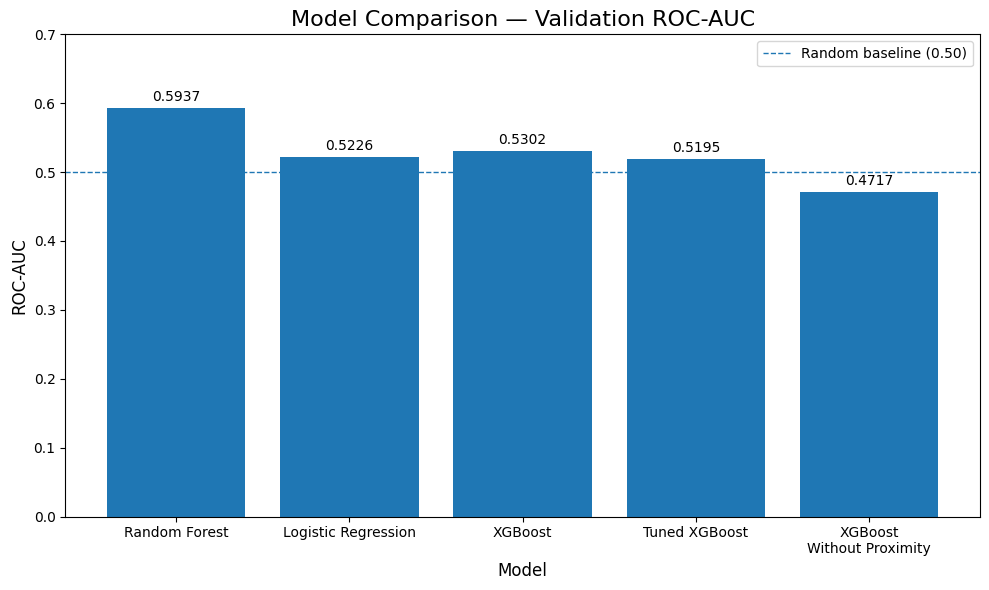

In [52]:
import matplotlib.pyplot as plt
import numpy as np

# Model comparison results
models = [
    "Random Forest",
    "Logistic Regression",
    "XGBoost",
    "Tuned XGBoost",
    "XGBoost\nWithout Proximity"
]

roc_auc = [
    0.5937,
    0.5226,
    0.5302,
    0.5195,
    0.4717
]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, roc_auc)

plt.title("Model Comparison — Validation ROC-AUC", fontsize=16)
plt.ylabel("ROC-AUC", fontsize=12)
plt.xlabel("Model", fontsize=12)

plt.ylim(0, 0.7)

# Add values above bars
for bar, value in zip(bars, roc_auc):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        fontsize=10
    )

plt.axhline(
    y=0.5,
    linestyle="--",
    linewidth=1,
    label="Random baseline (0.50)"
)

plt.legend()
plt.tight_layout()

plt.savefig("model_comparison_roc_auc.png", dpi=300, bbox_inches="tight")

plt.show()

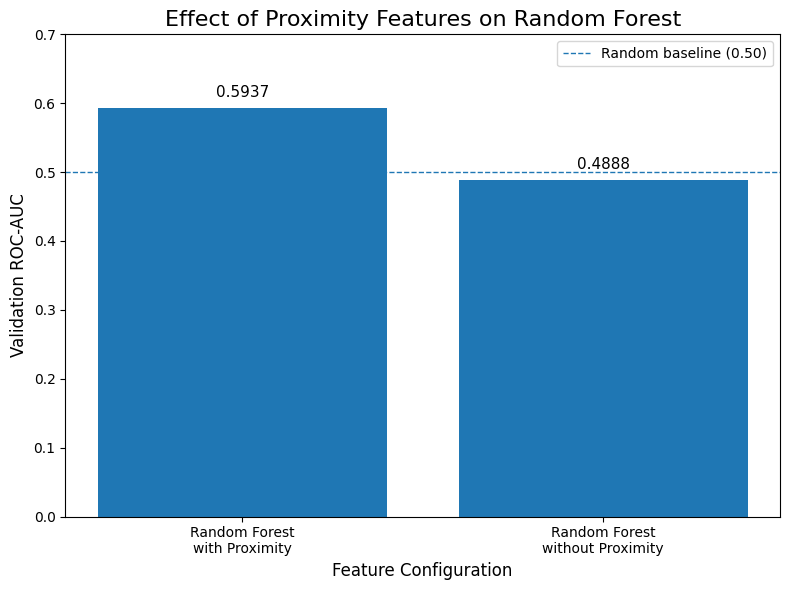

In [53]:
import matplotlib.pyplot as plt

# Proximity ablation results
models = [
    "Random Forest\nwith Proximity",
    "Random Forest\nwithout Proximity"
]

roc_auc = [
    0.5937,
    0.4888
]

plt.figure(figsize=(8, 6))

bars = plt.bar(models, roc_auc)

plt.title("Effect of Proximity Features on Random Forest", fontsize=16)
plt.ylabel("Validation ROC-AUC", fontsize=12)
plt.xlabel("Feature Configuration", fontsize=12)

plt.ylim(0, 0.7)

# Add values above bars
for bar, value in zip(bars, roc_auc):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.4f}",
        ha="center",
        fontsize=11
    )

# Random baseline
plt.axhline(
    y=0.5,
    linestyle="--",
    linewidth=1,
    label="Random baseline (0.50)"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "proximity_ablation_roc_auc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 700x600 with 0 Axes>

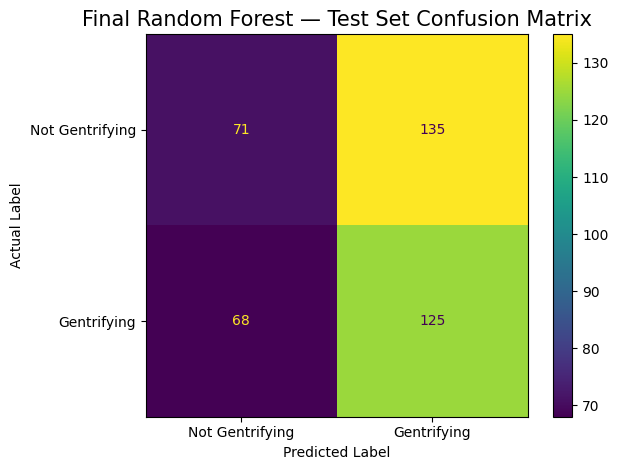

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Final Random Forest confusion matrix
cm = confusion_matrix(y_test, y_test_pred_final_rf)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Gentrifying", "Gentrifying"]
)

disp.plot(values_format="d")

plt.title("Final Random Forest — Test Set Confusion Matrix", fontsize=15)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    "final_random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [55]:
# ============================================================
# DATASET SUMMARY FOR REPORT
# ============================================================

print("DATASET SUMMARY")
print("=" * 50)

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nTarget distribution:")
print(df["housing_gentrification_label"].value_counts())

print("\nTarget proportions:")
print(df["housing_gentrification_label"].value_counts(normalize=True))

print("\nTrain / Validation / Test split:")
print(df["split"].value_counts())

print("\nNumber of ML features:", X.shape[1])

print("\nProximity features:")
for feature in proximity_features:
    print("-", feature)

print("\nMissing values in ML features:")
print(X.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

DATASET SUMMARY
Total rows: 7965
Total columns: 167

Target distribution:
housing_gentrification_label
1    4132
0    3833
Name: count, dtype: int64

Target proportions:
housing_gentrification_label
1    0.51877
0    0.48123
Name: proportion, dtype: float64

Train / Validation / Test split:
split
train         7168
test           399
validation     398
Name: count, dtype: int64

Number of ML features: 154

Proximity features:
- spatial_lag_housing_pre2012
- local_morans_I_housing_pre2012
- spatial_lag_income_pre2012
- local_morans_I_income_pre2012

Missing values in ML features:
0

Duplicate rows:
0


In [56]:
# ============================================================
# DATASET SUMMARY FOR REPORT
# ============================================================

print("DATASET SUMMARY")
print("=" * 50)

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nTarget distribution:")
print(df["housing_gentrification_label"].value_counts())

print("\nTarget proportions:")
print(df["housing_gentrification_label"].value_counts(normalize=True))

print("\nTrain / Validation / Test split:")
print(df["split"].value_counts())

print("\nNumber of ML features:", X.shape[1])

print("\nProximity features:")
for feature in proximity_features:
    print("-", feature)

print("\nMissing values in ML features:")
print(X.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

DATASET SUMMARY
Total rows: 7965
Total columns: 167

Target distribution:
housing_gentrification_label
1    4132
0    3833
Name: count, dtype: int64

Target proportions:
housing_gentrification_label
1    0.51877
0    0.48123
Name: proportion, dtype: float64

Train / Validation / Test split:
split
train         7168
test           399
validation     398
Name: count, dtype: int64

Number of ML features: 154

Proximity features:
- spatial_lag_housing_pre2012
- local_morans_I_housing_pre2012
- spatial_lag_income_pre2012
- local_morans_I_income_pre2012

Missing values in ML features:
0

Duplicate rows:
0


In [60]:
from IPython.display import Markdown, display

display(Markdown("""
# Dataset Description

The project uses a prepared California Census-tract-level dataset for predicting the binary target variable `housing_gentrification_label`.

The dataset contains **7,965 observations** and **167 columns**. After removing identifiers, target-related variables, split metadata, and other excluded columns, **154 features** are used for machine learning.

## Target Distribution

The target variable contains two classes:

- **0 = Not Gentrifying:** 3,833 observations (48.12%)
- **1 = Gentrifying:** 4,132 observations (51.88%)

## Dataset Split

The dataset is divided into three predefined subsets:

- **Training set:** 7,168 observations
- **Validation set:** 398 observations
- **Test set:** 399 observations

## Proximity-Based Features

Four proximity-based features are included:

1. `spatial_lag_housing_pre2012`
2. `local_morans_I_housing_pre2012`
3. `spatial_lag_income_pre2012`
4. `local_morans_I_income_pre2012`

There are **no missing values among the 154 machine-learning features**, and the dataset contains **no duplicate rows**.

# Target Variable

The prediction target is `housing_gentrification_label`.

The prepared dataset provides this as a binary classification label:

- **0 = Not Gentrifying**
- **1 = Gentrifying**

The target-generation procedure is not recomputed in the project notebook; the label is used as supplied in the prepared dataset.

# Preprocessing and Feature Selection

The following columns are excluded from the machine-learning feature matrix:

- `tract_id`
- `state_fips`
- `county_fips`
- `tract_code`
- `housing_cost_response`
- `housing_gentrification_score`
- `housing_gentrification_label`
- `income_hellinger_response`
- `income_gentrification_score`
- `income_gentrification_label`
- `pre_housing_change`
- `pre_income_change`
- `split`

After these exclusions, **154 features** remain for model training.

The four proximity-based features are retained in the main feature set because the project specifically investigates whether information from neighboring tracts provides useful predictive signal.
"""))


# Dataset Description

The project uses a prepared California Census-tract-level dataset for predicting the binary target variable `housing_gentrification_label`.

The dataset contains **7,965 observations** and **167 columns**. After removing identifiers, target-related variables, split metadata, and other excluded columns, **154 features** are used for machine learning.

## Target Distribution

The target variable contains two classes:

- **0 = Not Gentrifying:** 3,833 observations (48.12%)
- **1 = Gentrifying:** 4,132 observations (51.88%)

## Dataset Split

The dataset is divided into three predefined subsets:

- **Training set:** 7,168 observations
- **Validation set:** 398 observations
- **Test set:** 399 observations

## Proximity-Based Features

Four proximity-based features are included:

1. `spatial_lag_housing_pre2012`
2. `local_morans_I_housing_pre2012`
3. `spatial_lag_income_pre2012`
4. `local_morans_I_income_pre2012`

There are **no missing values among the 154 machine-learning features**, and the dataset contains **no duplicate rows**.

# Target Variable

The prediction target is `housing_gentrification_label`.

The prepared dataset provides this as a binary classification label:

- **0 = Not Gentrifying**
- **1 = Gentrifying**

The target-generation procedure is not recomputed in the project notebook; the label is used as supplied in the prepared dataset.

# Preprocessing and Feature Selection

The following columns are excluded from the machine-learning feature matrix:

- `tract_id`
- `state_fips`
- `county_fips`
- `tract_code`
- `housing_cost_response`
- `housing_gentrification_score`
- `housing_gentrification_label`
- `income_hellinger_response`
- `income_gentrification_score`
- `income_gentrification_label`
- `pre_housing_change`
- `pre_income_change`
- `split`

After these exclusions, **154 features** remain for model training.

The four proximity-based features are retained in the main feature set because the project specifically investigates whether information from neighboring tracts provides useful predictive signal.


In [61]:
from IPython.display import Markdown, display

display(Markdown("""
# Machine Learning Methodology

## Problem Formulation

The project is formulated as a **binary classification problem**.

The objective is to predict whether a California Census tract is classified as:

- **0 = Not Gentrifying**
- **1 = Gentrifying**

using historical tract-level features and proximity-based spatial features.

The machine-learning feature matrix contains **154 features**.

## Models Evaluated

Four main machine-learning approaches were evaluated:

### 1. Random Forest

A Random Forest classifier with **300 decision trees** was trained using:

- `n_estimators = 300`
- `random_state = 42`
- `n_jobs = -1`

Random Forest was selected for further evaluation because it achieved the strongest validation performance among the tested models.

### 2. Logistic Regression

A Logistic Regression model was trained using feature standardization with `StandardScaler`.

The Logistic Regression model used:

- `max_iter = 2000`

Standardization was applied because Logistic Regression is sensitive to the scale of numerical features.

### 3. XGBoost

An XGBoost classifier was evaluated using the following baseline configuration:

- `n_estimators = 300`
- `max_depth = 5`
- `learning_rate = 0.05`
- `subsample = 0.8`
- `colsample_bytree = 0.8`
- `random_state = 42`
- `eval_metric = logloss`

### 4. Tuned XGBoost

Randomized hyperparameter search with cross-validation was also performed for XGBoost.

The selected parameters were:

- `subsample = 0.9`
- `reg_lambda = 5`
- `n_estimators = 300`
- `min_child_weight = 5`
- `max_depth = 4`
- `learning_rate = 0.08`
- `colsample_bytree = 1.0`

The best cross-validation ROC-AUC obtained during tuning was approximately **0.5389**.

## Evaluation Metrics

The models were evaluated using:

- **Accuracy**
- **Precision**
- **Recall**
- **F1 Score**
- **ROC-AUC**

ROC-AUC was given particular importance because it evaluates the model's ability to distinguish between the two classes across classification thresholds.

## Validation and Test Strategy

The prepared dataset already contains predefined training, validation, and test splits.

The split sizes are:

- Training: **7,168 observations**
- Validation: **398 observations**
- Test: **399 observations**

The validation set was used for model comparison and selection.

After Random Forest was selected based on validation performance, the final Random Forest was retrained using the combined training and validation data:

**7,168 + 398 = 7,566 observations**

The test set containing **399 observations** was then used for the final evaluation.

The test set was not used during model selection.

# Proximity-Based Feature Analysis

A key part of the project is evaluating whether information from neighboring Census tracts provides useful predictive signal.

Four proximity-based features were included:

- `spatial_lag_housing_pre2012`
- `local_morans_I_housing_pre2012`
- `spatial_lag_income_pre2012`
- `local_morans_I_income_pre2012`

## Proximity Ablation Experiment

To measure the contribution of these features, an ablation experiment was performed.

Two Random Forest configurations were compared on the validation set:

1. Random Forest with all **154 features**, including proximity features.
2. Random Forest with the four proximity features removed, leaving **150 features**.

The validation ROC-AUC values were:

- **With proximity:** 0.5937
- **Without proximity:** 0.4888

The difference was:

**0.5937 - 0.4888 = 0.1049**

This indicates that the proximity features provided useful predictive signal for Random Forest on the validation split.

This result should be interpreted as a predictive association rather than evidence that proximity features cause gentrification.
"""))


# Machine Learning Methodology

## Problem Formulation

The project is formulated as a **binary classification problem**.

The objective is to predict whether a California Census tract is classified as:

- **0 = Not Gentrifying**
- **1 = Gentrifying**

using historical tract-level features and proximity-based spatial features.

The machine-learning feature matrix contains **154 features**.

## Models Evaluated

Four main machine-learning approaches were evaluated:

### 1. Random Forest

A Random Forest classifier with **300 decision trees** was trained using:

- `n_estimators = 300`
- `random_state = 42`
- `n_jobs = -1`

Random Forest was selected for further evaluation because it achieved the strongest validation performance among the tested models.

### 2. Logistic Regression

A Logistic Regression model was trained using feature standardization with `StandardScaler`.

The Logistic Regression model used:

- `max_iter = 2000`

Standardization was applied because Logistic Regression is sensitive to the scale of numerical features.

### 3. XGBoost

An XGBoost classifier was evaluated using the following baseline configuration:

- `n_estimators = 300`
- `max_depth = 5`
- `learning_rate = 0.05`
- `subsample = 0.8`
- `colsample_bytree = 0.8`
- `random_state = 42`
- `eval_metric = logloss`

### 4. Tuned XGBoost

Randomized hyperparameter search with cross-validation was also performed for XGBoost.

The selected parameters were:

- `subsample = 0.9`
- `reg_lambda = 5`
- `n_estimators = 300`
- `min_child_weight = 5`
- `max_depth = 4`
- `learning_rate = 0.08`
- `colsample_bytree = 1.0`

The best cross-validation ROC-AUC obtained during tuning was approximately **0.5389**.

## Evaluation Metrics

The models were evaluated using:

- **Accuracy**
- **Precision**
- **Recall**
- **F1 Score**
- **ROC-AUC**

ROC-AUC was given particular importance because it evaluates the model's ability to distinguish between the two classes across classification thresholds.

## Validation and Test Strategy

The prepared dataset already contains predefined training, validation, and test splits.

The split sizes are:

- Training: **7,168 observations**
- Validation: **398 observations**
- Test: **399 observations**

The validation set was used for model comparison and selection.

After Random Forest was selected based on validation performance, the final Random Forest was retrained using the combined training and validation data:

**7,168 + 398 = 7,566 observations**

The test set containing **399 observations** was then used for the final evaluation.

The test set was not used during model selection.

# Proximity-Based Feature Analysis

A key part of the project is evaluating whether information from neighboring Census tracts provides useful predictive signal.

Four proximity-based features were included:

- `spatial_lag_housing_pre2012`
- `local_morans_I_housing_pre2012`
- `spatial_lag_income_pre2012`
- `local_morans_I_income_pre2012`

## Proximity Ablation Experiment

To measure the contribution of these features, an ablation experiment was performed.

Two Random Forest configurations were compared on the validation set:

1. Random Forest with all **154 features**, including proximity features.
2. Random Forest with the four proximity features removed, leaving **150 features**.

The validation ROC-AUC values were:

- **With proximity:** 0.5937
- **Without proximity:** 0.4888

The difference was:

**0.5937 - 0.4888 = 0.1049**

This indicates that the proximity features provided useful predictive signal for Random Forest on the validation split.

This result should be interpreted as a predictive association rather than evidence that proximity features cause gentrification.


In [62]:
from IPython.display import Markdown, display

display(Markdown("""
# Results and Analysis

## Model Comparison

The validation performance of the evaluated models was:

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Random Forest | 0.5754 | 0.5844 | 0.6762 | 0.6269 | 0.5937 |
| Logistic Regression | 0.5101 | 0.5301 | 0.6286 | 0.5752 | 0.5226 |
| XGBoost | 0.5302 | 0.5535 | 0.5667 | 0.5600 | 0.5302 |
| Tuned XGBoost | 0.5276 | 0.5514 | 0.5619 | 0.5566 | 0.5195 |
| XGBoost Without Proximity | 0.4874 | 0.5143 | 0.5143 | 0.5143 | 0.4717 |
| Random Forest Without Proximity | 0.4950 | 0.5181 | 0.6143 | 0.5621 | 0.4888 |

Random Forest achieved the strongest validation performance among the evaluated models, with a validation accuracy of **57.54%**, F1 score of **62.69%**, and ROC-AUC of **59.37%**.

Therefore, Random Forest was selected for the final test evaluation.

## Proximity Ablation Results

The Random Forest proximity ablation experiment produced:

| Feature Configuration | Validation ROC-AUC |
|---|---:|
| With proximity features | **0.5937** |
| Without proximity features | **0.4888** |

Removing the four proximity features reduced ROC-AUC by:

**0.5937 - 0.4888 = 0.1049**

This suggests that the proximity-based features contained useful predictive information for the Random Forest model on the validation split.

The result demonstrates the relevance of incorporating spatial information into the modelling approach. However, it should be interpreted as predictive association and not as evidence of a causal relationship.

## Final Random Forest Test Results

After model selection, the Random Forest was retrained using the combined training and validation datasets containing **7,566 observations**.

The final model was evaluated on the untouched test set containing **399 observations**.

The final test results were:

| Metric | Test Result |
|---|---:|
| Accuracy | **49.12%** |
| Precision | **48.08%** |
| Recall | **64.77%** |
| F1 Score | **55.19%** |
| ROC-AUC | **51.25%** |

The final test ROC-AUC of **0.5125** indicates that the model had limited ability to distinguish between the two classes on unseen data.

Although the validation results were stronger, the reduction in performance on the test set indicates that the model did not generalize strongly to the unseen observations.

## Confusion Matrix Analysis

The final Random Forest produced the following confusion matrix on the test set:

| Actual / Predicted | Not Gentrifying | Gentrifying |
|---|---:|---:|
| Not Gentrifying | 71 | 135 |
| Gentrifying | 68 | 125 |

The model correctly classified:

- **71** Not Gentrifying observations.
- **125** Gentrifying observations.

It incorrectly classified:

- **135** Not Gentrifying observations as Gentrifying.
- **68** Gentrifying observations as Not Gentrifying.

The model therefore showed a relatively high recall for the Gentrifying class (**64.77%**) but also produced a substantial number of false positives.

# Discussion

The experiments provide two main findings.

First, Random Forest performed better than Logistic Regression and the evaluated XGBoost configurations on the validation set.

Second, the proximity ablation experiment showed that removing the four spatial features substantially reduced Random Forest validation ROC-AUC. This indicates that neighboring-tract information can provide useful predictive signal in this modelling setup.

However, the final test performance was considerably weaker than the validation performance. The final ROC-AUC of **0.5125** is only slightly above the random-classification level of 0.50. Therefore, the current model should not be considered a highly reliable real-world gentrification prediction system.

# Limitations

Several limitations should be considered:

1. The final model showed weak generalization on the unseen test set.

2. The target-generation procedure is not recomputed in the project notebook because the target label is supplied in the prepared dataset.

3. The proximity analysis demonstrates predictive association but does not establish causality.

4. The current feature and modelling setup may not capture all socioeconomic, housing-market, demographic, and geographic factors associated with gentrification.

5. The validation improvement from proximity features did not translate into strong final test performance.

# Conclusion

This project investigated a proximity-based machine-learning approach for providing an early warning signal for gentrification across California Census tracts.

Multiple classification models were evaluated, with Random Forest achieving the strongest validation performance. The proximity ablation experiment showed that spatial features provided useful predictive information during validation.

However, the final Random Forest achieved a test ROC-AUC of **0.5125**, indicating weak generalization to unseen data.

Therefore, the current system should be viewed as an experimental proof of concept rather than a reliable deployment-ready early warning system.

The results suggest that incorporating spatial relationships is promising, but stronger generalization would require further work in feature engineering, spatial and temporal validation, target construction, and additional data sources.

# Future Work

Potential improvements include:

- Developing richer spatial features describing neighboring socioeconomic changes.
- Using stronger spatial and temporal validation strategies.
- Exploring additional historical housing and demographic indicators.
- Improving the target-label construction and validation.
- Testing additional machine-learning and ensemble approaches.
- Investigating more robust spatial modelling techniques.
- Evaluating the system across different geographic regions and time periods.
"""))


# Results and Analysis

## Model Comparison

The validation performance of the evaluated models was:

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Random Forest | 0.5754 | 0.5844 | 0.6762 | 0.6269 | 0.5937 |
| Logistic Regression | 0.5101 | 0.5301 | 0.6286 | 0.5752 | 0.5226 |
| XGBoost | 0.5302 | 0.5535 | 0.5667 | 0.5600 | 0.5302 |
| Tuned XGBoost | 0.5276 | 0.5514 | 0.5619 | 0.5566 | 0.5195 |
| XGBoost Without Proximity | 0.4874 | 0.5143 | 0.5143 | 0.5143 | 0.4717 |
| Random Forest Without Proximity | 0.4950 | 0.5181 | 0.6143 | 0.5621 | 0.4888 |

Random Forest achieved the strongest validation performance among the evaluated models, with a validation accuracy of **57.54%**, F1 score of **62.69%**, and ROC-AUC of **59.37%**.

Therefore, Random Forest was selected for the final test evaluation.

## Proximity Ablation Results

The Random Forest proximity ablation experiment produced:

| Feature Configuration | Validation ROC-AUC |
|---|---:|
| With proximity features | **0.5937** |
| Without proximity features | **0.4888** |

Removing the four proximity features reduced ROC-AUC by:

**0.5937 - 0.4888 = 0.1049**

This suggests that the proximity-based features contained useful predictive information for the Random Forest model on the validation split.

The result demonstrates the relevance of incorporating spatial information into the modelling approach. However, it should be interpreted as predictive association and not as evidence of a causal relationship.

## Final Random Forest Test Results

After model selection, the Random Forest was retrained using the combined training and validation datasets containing **7,566 observations**.

The final model was evaluated on the untouched test set containing **399 observations**.

The final test results were:

| Metric | Test Result |
|---|---:|
| Accuracy | **49.12%** |
| Precision | **48.08%** |
| Recall | **64.77%** |
| F1 Score | **55.19%** |
| ROC-AUC | **51.25%** |

The final test ROC-AUC of **0.5125** indicates that the model had limited ability to distinguish between the two classes on unseen data.

Although the validation results were stronger, the reduction in performance on the test set indicates that the model did not generalize strongly to the unseen observations.

## Confusion Matrix Analysis

The final Random Forest produced the following confusion matrix on the test set:

| Actual / Predicted | Not Gentrifying | Gentrifying |
|---|---:|---:|
| Not Gentrifying | 71 | 135 |
| Gentrifying | 68 | 125 |

The model correctly classified:

- **71** Not Gentrifying observations.
- **125** Gentrifying observations.

It incorrectly classified:

- **135** Not Gentrifying observations as Gentrifying.
- **68** Gentrifying observations as Not Gentrifying.

The model therefore showed a relatively high recall for the Gentrifying class (**64.77%**) but also produced a substantial number of false positives.

# Discussion

The experiments provide two main findings.

First, Random Forest performed better than Logistic Regression and the evaluated XGBoost configurations on the validation set.

Second, the proximity ablation experiment showed that removing the four spatial features substantially reduced Random Forest validation ROC-AUC. This indicates that neighboring-tract information can provide useful predictive signal in this modelling setup.

However, the final test performance was considerably weaker than the validation performance. The final ROC-AUC of **0.5125** is only slightly above the random-classification level of 0.50. Therefore, the current model should not be considered a highly reliable real-world gentrification prediction system.

# Limitations

Several limitations should be considered:

1. The final model showed weak generalization on the unseen test set.

2. The target-generation procedure is not recomputed in the project notebook because the target label is supplied in the prepared dataset.

3. The proximity analysis demonstrates predictive association but does not establish causality.

4. The current feature and modelling setup may not capture all socioeconomic, housing-market, demographic, and geographic factors associated with gentrification.

5. The validation improvement from proximity features did not translate into strong final test performance.

# Conclusion

This project investigated a proximity-based machine-learning approach for providing an early warning signal for gentrification across California Census tracts.

Multiple classification models were evaluated, with Random Forest achieving the strongest validation performance. The proximity ablation experiment showed that spatial features provided useful predictive information during validation.

However, the final Random Forest achieved a test ROC-AUC of **0.5125**, indicating weak generalization to unseen data.

Therefore, the current system should be viewed as an experimental proof of concept rather than a reliable deployment-ready early warning system.

The results suggest that incorporating spatial relationships is promising, but stronger generalization would require further work in feature engineering, spatial and temporal validation, target construction, and additional data sources.

# Future Work

Potential improvements include:

- Developing richer spatial features describing neighboring socioeconomic changes.
- Using stronger spatial and temporal validation strategies.
- Exploring additional historical housing and demographic indicators.
- Improving the target-label construction and validation.
- Testing additional machine-learning and ensemble approaches.
- Investigating more robust spatial modelling techniques.
- Evaluating the system across different geographic regions and time periods.


In [63]:
from IPython.display import Markdown, display

display(Markdown("""
# Final Project Summary

## Project
**A Proximity-Based Early Warning System for Gentrification in California**

## Objective
The objective of this project is to investigate whether machine-learning models can provide an early warning signal for gentrification at the California Census Tract level by using historical socioeconomic and housing-related information together with proximity-based spatial features.

## Dataset
- Observations: **7,965 Census Tracts**
- Total columns: **167**
- Machine-learning features: **154**
- Training observations: **7,168**
- Validation observations: **398**
- Test observations: **399**
- Target: **housing_gentrification_label**
- Class 0: **3,833 observations**
- Class 1: **4,132 observations**
- Missing values in ML features: **0**

## Models Evaluated
- Logistic Regression
- Random Forest
- XGBoost
- Tuned XGBoost
- XGBoost without proximity features
- Random Forest without proximity features

## Best Validation Model
**Random Forest**

- Accuracy: **57.54%**
- Precision: **58.44%**
- Recall: **67.62%**
- F1 Score: **62.69%**
- ROC-AUC: **59.37%**

## Proximity Feature Finding

Random Forest validation ROC-AUC:

- With proximity features: **59.37%**
- Without proximity features: **48.88%**
- Difference: **10.49 percentage points**

This indicates that proximity features provided useful predictive signal in the validation experiment.

## Final Test Result

The final Random Forest was retrained using the training and validation observations and evaluated on the untouched test set.

- Accuracy: **49.12%**
- Precision: **48.08%**
- Recall: **64.77%**
- F1 Score: **55.19%**
- ROC-AUC: **51.25%**

## Overall Finding

The experiments suggest that spatial proximity information can improve predictive performance during validation. However, the final test performance was weak, indicating limited generalization to unseen data.

Therefore, the developed system should be considered an **experimental proof of concept**, rather than a deployment-ready gentrification prediction system.

Further improvements would require stronger feature engineering, improved spatial and temporal validation, better target construction, and additional socioeconomic and housing-market information.
"""))


# Final Project Summary

## Project
**A Proximity-Based Early Warning System for Gentrification in California**

## Objective
The objective of this project is to investigate whether machine-learning models can provide an early warning signal for gentrification at the California Census Tract level by using historical socioeconomic and housing-related information together with proximity-based spatial features.

## Dataset
- Observations: **7,965 Census Tracts**
- Total columns: **167**
- Machine-learning features: **154**
- Training observations: **7,168**
- Validation observations: **398**
- Test observations: **399**
- Target: **housing_gentrification_label**
- Class 0: **3,833 observations**
- Class 1: **4,132 observations**
- Missing values in ML features: **0**

## Models Evaluated
- Logistic Regression
- Random Forest
- XGBoost
- Tuned XGBoost
- XGBoost without proximity features
- Random Forest without proximity features

## Best Validation Model
**Random Forest**

- Accuracy: **57.54%**
- Precision: **58.44%**
- Recall: **67.62%**
- F1 Score: **62.69%**
- ROC-AUC: **59.37%**

## Proximity Feature Finding

Random Forest validation ROC-AUC:

- With proximity features: **59.37%**
- Without proximity features: **48.88%**
- Difference: **10.49 percentage points**

This indicates that proximity features provided useful predictive signal in the validation experiment.

## Final Test Result

The final Random Forest was retrained using the training and validation observations and evaluated on the untouched test set.

- Accuracy: **49.12%**
- Precision: **48.08%**
- Recall: **64.77%**
- F1 Score: **55.19%**
- ROC-AUC: **51.25%**

## Overall Finding

The experiments suggest that spatial proximity information can improve predictive performance during validation. However, the final test performance was weak, indicating limited generalization to unseen data.

Therefore, the developed system should be considered an **experimental proof of concept**, rather than a deployment-ready gentrification prediction system.

Further improvements would require stronger feature engineering, improved spatial and temporal validation, better target construction, and additional socioeconomic and housing-market information.


In [65]:
from IPython.display import Markdown, display

display(Markdown("""
# Abstract

Gentrification is a complex socioeconomic process associated with changes in housing conditions, costs, income distributions, and neighborhood characteristics. This project investigates a proximity-based machine-learning approach for providing an early warning signal for gentrification across California Census Tracts.

The prepared dataset contains **7,965 observations and 167 columns**, including **154 machine-learning features** after excluding identifiers, target-related variables, and other non-predictive fields. Four proximity-based spatial features were incorporated to capture information related to neighboring Census Tracts.

Multiple classification approaches were evaluated, including Logistic Regression, Random Forest, XGBoost, and a tuned XGBoost model. Random Forest achieved the strongest validation performance, obtaining an accuracy of **57.54%**, F1 score of **62.69%**, and ROC-AUC of **59.37%**.

A proximity ablation experiment showed that removing the proximity features reduced Random Forest validation ROC-AUC from **59.37% to 48.88%**, suggesting that spatial information provided useful predictive signal during validation.

The final Random Forest was retrained using the combined training and validation data and evaluated on an untouched test set of 399 observations. It achieved an accuracy of **49.12%**, F1 score of **55.19%**, and ROC-AUC of **51.25%**. The relatively low test ROC-AUC indicates weak generalization to unseen data.

Overall, the project demonstrates the potential usefulness of proximity-based features for gentrification modelling, while also highlighting the need for stronger feature engineering, validation strategies, target construction, and additional data before such a system could be considered reliable for real-world deployment.
"""))


# Abstract

Gentrification is a complex socioeconomic process associated with changes in housing conditions, costs, income distributions, and neighborhood characteristics. This project investigates a proximity-based machine-learning approach for providing an early warning signal for gentrification across California Census Tracts.

The prepared dataset contains **7,965 observations and 167 columns**, including **154 machine-learning features** after excluding identifiers, target-related variables, and other non-predictive fields. Four proximity-based spatial features were incorporated to capture information related to neighboring Census Tracts.

Multiple classification approaches were evaluated, including Logistic Regression, Random Forest, XGBoost, and a tuned XGBoost model. Random Forest achieved the strongest validation performance, obtaining an accuracy of **57.54%**, F1 score of **62.69%**, and ROC-AUC of **59.37%**.

A proximity ablation experiment showed that removing the proximity features reduced Random Forest validation ROC-AUC from **59.37% to 48.88%**, suggesting that spatial information provided useful predictive signal during validation.

The final Random Forest was retrained using the combined training and validation data and evaluated on an untouched test set of 399 observations. It achieved an accuracy of **49.12%**, F1 score of **55.19%**, and ROC-AUC of **51.25%**. The relatively low test ROC-AUC indicates weak generalization to unseen data.

Overall, the project demonstrates the potential usefulness of proximity-based features for gentrification modelling, while also highlighting the need for stronger feature engineering, validation strategies, target construction, and additional data before such a system could be considered reliable for real-world deployment.


In [66]:
from IPython.display import Markdown, display

display(Markdown("""
# 1. Problem Statement

Gentrification refers to a process in which the socioeconomic and housing characteristics of a neighborhood change over time. Such changes can involve variations in housing costs, income distributions, and other demographic or socioeconomic indicators.

The objective of this project is to investigate whether historical housing and socioeconomic information can be used with machine-learning techniques to provide an early warning signal for gentrification at the California Census Tract level.

A key component of the project is the use of **proximity-based spatial features**. Since neighboring Census Tracts can have related socioeconomic characteristics, information from nearby tracts is incorporated into the machine-learning feature set.

The problem is formulated as a **binary classification task**, where the model predicts the provided `housing_gentrification_label`.

## 1.1 Objectives

The main objectives of this project are:

1. To prepare and analyze a California Census Tract dataset for machine-learning-based gentrification classification.

2. To evaluate multiple classification algorithms, including:
   - Logistic Regression
   - Random Forest
   - XGBoost
   - Tuned XGBoost

3. To investigate whether proximity-based spatial features provide useful predictive information.

4. To compare model performance using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.

5. To select a model based on validation performance and evaluate its generalization on an unseen test dataset.

6. To analyze the limitations of the developed approach and identify possible directions for future improvement.

## 1.2 Research Question

The main research question investigated in this project is:

**Can historical socioeconomic and housing features, together with proximity-based spatial information, provide useful predictive signals for identifying Census Tracts associated with gentrification in California?**

## 1.3 Proximity-Based Approach

The project incorporates four proximity-related features:

- `spatial_lag_housing_pre2012`
- `local_morans_I_housing_pre2012`
- `spatial_lag_income_pre2012`
- `local_morans_I_income_pre2012`

These features are intended to capture spatial relationships between neighboring Census Tracts.

To investigate their contribution, an ablation experiment was performed by comparing model performance with and without the proximity features.

The experiment showed that proximity features provided useful predictive signal on the validation data. However, this result represents predictive association and should not be interpreted as proof that proximity features causally produce gentrification.
"""))


# 1. Problem Statement

Gentrification refers to a process in which the socioeconomic and housing characteristics of a neighborhood change over time. Such changes can involve variations in housing costs, income distributions, and other demographic or socioeconomic indicators.

The objective of this project is to investigate whether historical housing and socioeconomic information can be used with machine-learning techniques to provide an early warning signal for gentrification at the California Census Tract level.

A key component of the project is the use of **proximity-based spatial features**. Since neighboring Census Tracts can have related socioeconomic characteristics, information from nearby tracts is incorporated into the machine-learning feature set.

The problem is formulated as a **binary classification task**, where the model predicts the provided `housing_gentrification_label`.

## 1.1 Objectives

The main objectives of this project are:

1. To prepare and analyze a California Census Tract dataset for machine-learning-based gentrification classification.

2. To evaluate multiple classification algorithms, including:
   - Logistic Regression
   - Random Forest
   - XGBoost
   - Tuned XGBoost

3. To investigate whether proximity-based spatial features provide useful predictive information.

4. To compare model performance using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.

5. To select a model based on validation performance and evaluate its generalization on an unseen test dataset.

6. To analyze the limitations of the developed approach and identify possible directions for future improvement.

## 1.2 Research Question

The main research question investigated in this project is:

**Can historical socioeconomic and housing features, together with proximity-based spatial information, provide useful predictive signals for identifying Census Tracts associated with gentrification in California?**

## 1.3 Proximity-Based Approach

The project incorporates four proximity-related features:

- `spatial_lag_housing_pre2012`
- `local_morans_I_housing_pre2012`
- `spatial_lag_income_pre2012`
- `local_morans_I_income_pre2012`

These features are intended to capture spatial relationships between neighboring Census Tracts.

To investigate their contribution, an ablation experiment was performed by comparing model performance with and without the proximity features.

The experiment showed that proximity features provided useful predictive signal on the validation data. However, this result represents predictive association and should not be interpreted as proof that proximity features causally produce gentrification.


In [67]:
from IPython.display import Markdown, display

display(Markdown("""
# 2. Dataset Details

The project uses a prepared California Census Tract dataset for machine-learning-based gentrification classification.

## 2.1 Dataset Size

| Property | Value |
|---|---:|
| Total observations | 7,965 |
| Total columns | 167 |
| Machine-learning features | 154 |
| Training observations | 7,168 |
| Validation observations | 398 |
| Test observations | 399 |

The dataset contains **7,965 Census Tract observations** and **167 columns**. After excluding identifiers, target-related variables, split information, and other excluded variables, **154 features** were used for machine learning.

## 2.2 Target Variable

The prediction target is:

`housing_gentrification_label`

The target is treated as a binary classification variable.

| Class | Number of observations | Proportion |
|---|---:|---:|
| 0 | 3,833 | 48.12% |
| 1 | 4,132 | 51.88% |

The two classes are relatively balanced, although Class 1 contains slightly more observations.

## 2.3 Data Split

The prepared dataset contains predefined training, validation, and test partitions:

- Training: **7,168 observations**
- Validation: **398 observations**
- Test: **399 observations**

The validation set was used for comparing models and experiments.

After selecting the final Random Forest model, the model was retrained using the combined training and validation observations (**7,566 observations**) and evaluated on the untouched test set.

## 2.4 Feature Preparation

The machine-learning feature matrix excludes variables that should not be directly used as predictive inputs, including:

- Census Tract identifiers
- State and county identifiers
- Target variables
- Target-related response and score variables
- Predefined split information
- Other excluded change variables

The resulting machine-learning dataset contains **154 features**.

No missing values were present in the final machine-learning features.

## 2.5 Proximity Features

Four proximity-based features were included:

1. `spatial_lag_housing_pre2012`
2. `local_morans_I_housing_pre2012`
3. `spatial_lag_income_pre2012`
4. `local_morans_I_income_pre2012`

These variables provide spatial information related to neighboring Census Tracts and are central to the proximity-based component of the project.
"""))


# 2. Dataset Details

The project uses a prepared California Census Tract dataset for machine-learning-based gentrification classification.

## 2.1 Dataset Size

| Property | Value |
|---|---:|
| Total observations | 7,965 |
| Total columns | 167 |
| Machine-learning features | 154 |
| Training observations | 7,168 |
| Validation observations | 398 |
| Test observations | 399 |

The dataset contains **7,965 Census Tract observations** and **167 columns**. After excluding identifiers, target-related variables, split information, and other excluded variables, **154 features** were used for machine learning.

## 2.2 Target Variable

The prediction target is:

`housing_gentrification_label`

The target is treated as a binary classification variable.

| Class | Number of observations | Proportion |
|---|---:|---:|
| 0 | 3,833 | 48.12% |
| 1 | 4,132 | 51.88% |

The two classes are relatively balanced, although Class 1 contains slightly more observations.

## 2.3 Data Split

The prepared dataset contains predefined training, validation, and test partitions:

- Training: **7,168 observations**
- Validation: **398 observations**
- Test: **399 observations**

The validation set was used for comparing models and experiments.

After selecting the final Random Forest model, the model was retrained using the combined training and validation observations (**7,566 observations**) and evaluated on the untouched test set.

## 2.4 Feature Preparation

The machine-learning feature matrix excludes variables that should not be directly used as predictive inputs, including:

- Census Tract identifiers
- State and county identifiers
- Target variables
- Target-related response and score variables
- Predefined split information
- Other excluded change variables

The resulting machine-learning dataset contains **154 features**.

No missing values were present in the final machine-learning features.

## 2.5 Proximity Features

Four proximity-based features were included:

1. `spatial_lag_housing_pre2012`
2. `local_morans_I_housing_pre2012`
3. `spatial_lag_income_pre2012`
4. `local_morans_I_income_pre2012`

These variables provide spatial information related to neighboring Census Tracts and are central to the proximity-based component of the project.


In [68]:
from IPython.display import Markdown, display

display(Markdown("""
# 3. Methodology

The overall methodology consists of dataset preparation, model development, model comparison, proximity-feature analysis, final model selection, and test evaluation.

## 3.1 Overall Pipeline

The project follows the following workflow:

**Prepared Census Tract Dataset**

↓

**Feature Selection and Exclusion**

↓

**Training / Validation / Test Split**

↓

**Machine-Learning Models**

↓

**Validation-Based Model Comparison**

↓

**Proximity Feature Ablation**

↓

**Final Model Selection**

↓

**Retraining on Training + Validation Data**

↓

**Evaluation on Unseen Test Data**

## 3.2 Problem Formulation

The task is formulated as a binary classification problem.

For each Census Tract, the model receives a set of historical housing, socioeconomic, and spatial features and predicts the provided binary `housing_gentrification_label`.

## 3.3 Models Evaluated

Four main modelling approaches were investigated.

### Logistic Regression

Logistic Regression was used as a baseline linear classification model.

Before training, the input features were standardized using `StandardScaler`.

The Logistic Regression model used a maximum of 2,000 iterations to allow convergence.

### Random Forest

Random Forest was used to model potentially nonlinear relationships between the input features and the target.

The main configuration used:

- Number of trees: **300**
- Random state: **42**
- Parallel processing: enabled using all available CPU cores

### XGBoost

XGBoost was evaluated as a gradient-boosted tree model.

The baseline configuration used:

- Number of estimators: **300**
- Maximum depth: **5**
- Learning rate: **0.05**
- Subsample: **0.8**
- Column subsampling: **0.8**
- Random state: **42**

### Tuned XGBoost

Randomized hyperparameter search with three-fold cross-validation was used to investigate whether tuning could improve XGBoost performance.

The best cross-validation ROC-AUC obtained during tuning was **0.5389**.

The selected parameters were:

- Subsample: **0.9**
- Regularization lambda: **5**
- Number of estimators: **300**
- Minimum child weight: **5**
- Maximum depth: **4**
- Learning rate: **0.08**
- Column subsampling: **1.0**

## 3.4 Evaluation Metrics

The models were evaluated using:

### Accuracy

The proportion of all predictions that were correctly classified.

### Precision

The proportion of predicted positive observations that were actually positive.

### Recall

The proportion of actual positive observations correctly identified by the model.

### F1 Score

The harmonic mean of precision and recall.

### ROC-AUC

The area under the Receiver Operating Characteristic curve, measuring the model's ability to distinguish between the two classes across different classification thresholds.

## 3.5 Model Selection

Validation performance was used for comparing the candidate models.

Random Forest achieved the strongest validation performance and was therefore selected for the final evaluation.

The selected Random Forest was then retrained using the combined training and validation datasets before being evaluated on the untouched test set.
"""))


# 3. Methodology

The overall methodology consists of dataset preparation, model development, model comparison, proximity-feature analysis, final model selection, and test evaluation.

## 3.1 Overall Pipeline

The project follows the following workflow:

**Prepared Census Tract Dataset**

↓

**Feature Selection and Exclusion**

↓

**Training / Validation / Test Split**

↓

**Machine-Learning Models**

↓

**Validation-Based Model Comparison**

↓

**Proximity Feature Ablation**

↓

**Final Model Selection**

↓

**Retraining on Training + Validation Data**

↓

**Evaluation on Unseen Test Data**

## 3.2 Problem Formulation

The task is formulated as a binary classification problem.

For each Census Tract, the model receives a set of historical housing, socioeconomic, and spatial features and predicts the provided binary `housing_gentrification_label`.

## 3.3 Models Evaluated

Four main modelling approaches were investigated.

### Logistic Regression

Logistic Regression was used as a baseline linear classification model.

Before training, the input features were standardized using `StandardScaler`.

The Logistic Regression model used a maximum of 2,000 iterations to allow convergence.

### Random Forest

Random Forest was used to model potentially nonlinear relationships between the input features and the target.

The main configuration used:

- Number of trees: **300**
- Random state: **42**
- Parallel processing: enabled using all available CPU cores

### XGBoost

XGBoost was evaluated as a gradient-boosted tree model.

The baseline configuration used:

- Number of estimators: **300**
- Maximum depth: **5**
- Learning rate: **0.05**
- Subsample: **0.8**
- Column subsampling: **0.8**
- Random state: **42**

### Tuned XGBoost

Randomized hyperparameter search with three-fold cross-validation was used to investigate whether tuning could improve XGBoost performance.

The best cross-validation ROC-AUC obtained during tuning was **0.5389**.

The selected parameters were:

- Subsample: **0.9**
- Regularization lambda: **5**
- Number of estimators: **300**
- Minimum child weight: **5**
- Maximum depth: **4**
- Learning rate: **0.08**
- Column subsampling: **1.0**

## 3.4 Evaluation Metrics

The models were evaluated using:

### Accuracy

The proportion of all predictions that were correctly classified.

### Precision

The proportion of predicted positive observations that were actually positive.

### Recall

The proportion of actual positive observations correctly identified by the model.

### F1 Score

The harmonic mean of precision and recall.

### ROC-AUC

The area under the Receiver Operating Characteristic curve, measuring the model's ability to distinguish between the two classes across different classification thresholds.

## 3.5 Model Selection

Validation performance was used for comparing the candidate models.

Random Forest achieved the strongest validation performance and was therefore selected for the final evaluation.

The selected Random Forest was then retrained using the combined training and validation datasets before being evaluated on the untouched test set.


In [69]:
from IPython.display import Markdown, display

display(Markdown("""
# 4. Implementation Overview

The implementation was performed using Python in Google Colab.

## 4.1 Main Libraries

The implementation uses standard Python machine-learning and data-analysis libraries, including:

- **Pandas** for dataset loading and manipulation.
- **NumPy** for numerical operations.
- **Scikit-learn** for preprocessing, model training, evaluation metrics, and model comparison.
- **XGBoost** for gradient-boosted tree modelling.
- **Matplotlib** for visualization.

## 4.2 Data Loading

The prepared CSV dataset was loaded into a Pandas DataFrame.

The final dataset contains:

- 7,965 observations
- 167 columns

## 4.3 Feature and Target Separation

The target variable was separated from the input features.

The following target-related and identifier columns were excluded from the machine-learning feature matrix:

- `tract_id`
- `state_fips`
- `county_fips`
- `tract_code`
- `housing_cost_response`
- `housing_gentrification_score`
- `housing_gentrification_label`
- `income_hellinger_response`
- `income_gentrification_score`
- `income_gentrification_label`
- `pre_housing_change`
- `pre_income_change`
- `split`

The target was set to:

`housing_gentrification_label`

## 4.4 Train, Validation and Test Processing

The dataset's predefined `split` information was used to identify the training, validation, and test observations.

The resulting partitions were:

- Training: 7,168
- Validation: 398
- Test: 399

## 4.5 Model Training

Each candidate model was trained using the training partition.

The validation partition was then used to compare model performance.

For the final evaluation, the selected Random Forest model was retrained using both the training and validation observations.

The test set was kept separate until final evaluation.

## 4.6 Visualization

The project generated visualizations for:

1. Validation ROC-AUC model comparison.
2. Proximity-feature ablation.
3. Final Random Forest confusion matrix.

Feature-importance analysis was also performed using XGBoost feature importance and permutation importance.
"""))


# 4. Implementation Overview

The implementation was performed using Python in Google Colab.

## 4.1 Main Libraries

The implementation uses standard Python machine-learning and data-analysis libraries, including:

- **Pandas** for dataset loading and manipulation.
- **NumPy** for numerical operations.
- **Scikit-learn** for preprocessing, model training, evaluation metrics, and model comparison.
- **XGBoost** for gradient-boosted tree modelling.
- **Matplotlib** for visualization.

## 4.2 Data Loading

The prepared CSV dataset was loaded into a Pandas DataFrame.

The final dataset contains:

- 7,965 observations
- 167 columns

## 4.3 Feature and Target Separation

The target variable was separated from the input features.

The following target-related and identifier columns were excluded from the machine-learning feature matrix:

- `tract_id`
- `state_fips`
- `county_fips`
- `tract_code`
- `housing_cost_response`
- `housing_gentrification_score`
- `housing_gentrification_label`
- `income_hellinger_response`
- `income_gentrification_score`
- `income_gentrification_label`
- `pre_housing_change`
- `pre_income_change`
- `split`

The target was set to:

`housing_gentrification_label`

## 4.4 Train, Validation and Test Processing

The dataset's predefined `split` information was used to identify the training, validation, and test observations.

The resulting partitions were:

- Training: 7,168
- Validation: 398
- Test: 399

## 4.5 Model Training

Each candidate model was trained using the training partition.

The validation partition was then used to compare model performance.

For the final evaluation, the selected Random Forest model was retrained using both the training and validation observations.

The test set was kept separate until final evaluation.

## 4.6 Visualization

The project generated visualizations for:

1. Validation ROC-AUC model comparison.
2. Proximity-feature ablation.
3. Final Random Forest confusion matrix.

Feature-importance analysis was also performed using XGBoost feature importance and permutation importance.


In [70]:
from IPython.display import Markdown, display

display(Markdown("""
# 5. Feature Importance Analysis

Feature importance analysis was performed to investigate which input variables contributed most strongly to the XGBoost model's predictions.

Two approaches were examined:

1. Built-in XGBoost feature importance.
2. Permutation importance.

## 5.1 Built-in XGBoost Importance

The four proximity features appeared among the top 20 features according to the built-in XGBoost importance measure.

The highest-ranked proximity features included:

- `spatial_lag_housing_pre2012`
- `local_morans_I_housing_pre2012`
- `spatial_lag_income_pre2012`
- `local_morans_I_income_pre2012`

In particular, `spatial_lag_housing_pre2012` and `local_morans_I_housing_pre2012` were ranked first and second in the reported top-20 feature-importance results.

## 5.2 Permutation Importance

Permutation importance measures the reduction in model performance when individual features are randomly shuffled.

The highest-ranked feature was:

`local_morans_I_housing_pre2012`

with a mean permutation importance of approximately **0.0237**.

`spatial_lag_income_pre2012` was also among the highest-ranked features.

These findings provide additional evidence that spatial information was useful to the model.

However, feature importance should not be interpreted as causal influence. A feature being important for prediction does not establish that it directly causes gentrification.
"""))


# 5. Feature Importance Analysis

Feature importance analysis was performed to investigate which input variables contributed most strongly to the XGBoost model's predictions.

Two approaches were examined:

1. Built-in XGBoost feature importance.
2. Permutation importance.

## 5.1 Built-in XGBoost Importance

The four proximity features appeared among the top 20 features according to the built-in XGBoost importance measure.

The highest-ranked proximity features included:

- `spatial_lag_housing_pre2012`
- `local_morans_I_housing_pre2012`
- `spatial_lag_income_pre2012`
- `local_morans_I_income_pre2012`

In particular, `spatial_lag_housing_pre2012` and `local_morans_I_housing_pre2012` were ranked first and second in the reported top-20 feature-importance results.

## 5.2 Permutation Importance

Permutation importance measures the reduction in model performance when individual features are randomly shuffled.

The highest-ranked feature was:

`local_morans_I_housing_pre2012`

with a mean permutation importance of approximately **0.0237**.

`spatial_lag_income_pre2012` was also among the highest-ranked features.

These findings provide additional evidence that spatial information was useful to the model.

However, feature importance should not be interpreted as causal influence. A feature being important for prediction does not establish that it directly causes gentrification.


In [71]:
from IPython.display import Markdown, display

display(Markdown("""
# 6. Model Results

## 6.1 Validation Performance

The candidate models were evaluated on the validation dataset.

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Random Forest | **0.5754** | **0.5844** | **0.6762** | **0.6269** | **0.5937** |
| Logistic Regression | 0.5101 | 0.5301 | 0.6286 | 0.5752 | 0.5226 |
| XGBoost | 0.5302 | 0.5535 | 0.5667 | 0.5600 | 0.5302 |
| Tuned XGBoost | 0.5276 | 0.5514 | 0.5619 | 0.5566 | 0.5195 |
| XGBoost Without Proximity | 0.4874 | 0.5143 | 0.5143 | 0.5143 | 0.4717 |
| Random Forest Without Proximity | 0.4950 | 0.5181 | 0.6143 | 0.5621 | 0.4888 |

Random Forest achieved the highest validation ROC-AUC (**0.5937**) and the highest validation F1 score (**0.6269**) among the evaluated models.

It was therefore selected for final testing.

## 6.2 Proximity Ablation

The contribution of the proximity features was investigated by training a Random Forest model after removing the four proximity variables.

| Configuration | ROC-AUC |
|---|---:|
| Random Forest with proximity features | **0.5937** |
| Random Forest without proximity features | **0.4888** |

The difference was:

**0.5937 - 0.4888 = 0.1049**

Thus, removing the proximity features resulted in a **0.1049 decrease in validation ROC-AUC**.

This suggests that the proximity features contained useful predictive information in the validation experiment.

## 6.3 Validation ROC-AUC Interpretation

A ROC-AUC of 0.50 represents approximately random discrimination.

The Random Forest achieved a validation ROC-AUC of 0.5937, which indicates some ability to distinguish between the two classes on the validation split.

However, this performance should not be interpreted as strong predictive performance, especially because the final unseen-test performance was substantially lower.
"""))


# 6. Model Results

## 6.1 Validation Performance

The candidate models were evaluated on the validation dataset.

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Random Forest | **0.5754** | **0.5844** | **0.6762** | **0.6269** | **0.5937** |
| Logistic Regression | 0.5101 | 0.5301 | 0.6286 | 0.5752 | 0.5226 |
| XGBoost | 0.5302 | 0.5535 | 0.5667 | 0.5600 | 0.5302 |
| Tuned XGBoost | 0.5276 | 0.5514 | 0.5619 | 0.5566 | 0.5195 |
| XGBoost Without Proximity | 0.4874 | 0.5143 | 0.5143 | 0.5143 | 0.4717 |
| Random Forest Without Proximity | 0.4950 | 0.5181 | 0.6143 | 0.5621 | 0.4888 |

Random Forest achieved the highest validation ROC-AUC (**0.5937**) and the highest validation F1 score (**0.6269**) among the evaluated models.

It was therefore selected for final testing.

## 6.2 Proximity Ablation

The contribution of the proximity features was investigated by training a Random Forest model after removing the four proximity variables.

| Configuration | ROC-AUC |
|---|---:|
| Random Forest with proximity features | **0.5937** |
| Random Forest without proximity features | **0.4888** |

The difference was:

**0.5937 - 0.4888 = 0.1049**

Thus, removing the proximity features resulted in a **0.1049 decrease in validation ROC-AUC**.

This suggests that the proximity features contained useful predictive information in the validation experiment.

## 6.3 Validation ROC-AUC Interpretation

A ROC-AUC of 0.50 represents approximately random discrimination.

The Random Forest achieved a validation ROC-AUC of 0.5937, which indicates some ability to distinguish between the two classes on the validation split.

However, this performance should not be interpreted as strong predictive performance, especially because the final unseen-test performance was substantially lower.


In [72]:
from IPython.display import Markdown, display

display(Markdown("""
# 7. Final Model Evaluation

## 7.1 Final Model

Based on validation performance, Random Forest was selected as the final model.

The model was retrained using the combined training and validation observations:

**7,168 + 398 = 7,566 observations**

The untouched test set contained **399 observations**.

## 7.2 Test Performance

The final Random Forest achieved:

| Metric | Test Result |
|---|---:|
| Accuracy | **49.12%** |
| Precision | **48.08%** |
| Recall | **64.77%** |
| F1 Score | **55.19%** |
| ROC-AUC | **51.25%** |

The test ROC-AUC of **0.5125** is only slightly above the random baseline of 0.50.

This indicates that the final model had limited ability to distinguish between gentrifying and non-gentrifying observations on unseen data.

## 7.3 Confusion Matrix

The final test confusion matrix was:

| Actual / Predicted | Not Gentrifying | Gentrifying |
|---|---:|---:|
| Not Gentrifying | 71 | 135 |
| Gentrifying | 68 | 125 |

The model correctly identified:

- 71 Not Gentrifying observations.
- 125 Gentrifying observations.

The model incorrectly classified:

- 135 Not Gentrifying observations as Gentrifying.
- 68 Gentrifying observations as Not Gentrifying.

The relatively high recall for the Gentrifying class (**64.77%**) indicates that the model identified a substantial proportion of the actual positive cases.

However, the large number of false positives resulted in relatively low precision.

## 7.4 Generalization

The difference between validation and test performance is an important finding.

The Random Forest achieved a validation ROC-AUC of **0.5937**, but the final test ROC-AUC was only **0.5125**.

This indicates that the validation performance did not translate strongly to unseen data.

Consequently, the current model should be regarded as an experimental proof of concept rather than a reliable deployment-ready prediction system.
"""))


# 7. Final Model Evaluation

## 7.1 Final Model

Based on validation performance, Random Forest was selected as the final model.

The model was retrained using the combined training and validation observations:

**7,168 + 398 = 7,566 observations**

The untouched test set contained **399 observations**.

## 7.2 Test Performance

The final Random Forest achieved:

| Metric | Test Result |
|---|---:|
| Accuracy | **49.12%** |
| Precision | **48.08%** |
| Recall | **64.77%** |
| F1 Score | **55.19%** |
| ROC-AUC | **51.25%** |

The test ROC-AUC of **0.5125** is only slightly above the random baseline of 0.50.

This indicates that the final model had limited ability to distinguish between gentrifying and non-gentrifying observations on unseen data.

## 7.3 Confusion Matrix

The final test confusion matrix was:

| Actual / Predicted | Not Gentrifying | Gentrifying |
|---|---:|---:|
| Not Gentrifying | 71 | 135 |
| Gentrifying | 68 | 125 |

The model correctly identified:

- 71 Not Gentrifying observations.
- 125 Gentrifying observations.

The model incorrectly classified:

- 135 Not Gentrifying observations as Gentrifying.
- 68 Gentrifying observations as Not Gentrifying.

The relatively high recall for the Gentrifying class (**64.77%**) indicates that the model identified a substantial proportion of the actual positive cases.

However, the large number of false positives resulted in relatively low precision.

## 7.4 Generalization

The difference between validation and test performance is an important finding.

The Random Forest achieved a validation ROC-AUC of **0.5937**, but the final test ROC-AUC was only **0.5125**.

This indicates that the validation performance did not translate strongly to unseen data.

Consequently, the current model should be regarded as an experimental proof of concept rather than a reliable deployment-ready prediction system.


In [73]:
from IPython.display import Markdown, display

display(Markdown("""
# 8. Discussion and Limitations

## 8.1 Discussion

The experiments produced two important observations.

First, Random Forest achieved the strongest validation performance among the evaluated models. Its validation ROC-AUC was **0.5937**, compared with 0.5226 for Logistic Regression and 0.5302 for baseline XGBoost.

Second, the proximity ablation experiment showed that removing the spatial features reduced Random Forest validation ROC-AUC from **0.5937 to 0.4888**.

This indicates that the spatial information captured by the proximity features provided useful predictive signal on the validation dataset.

However, the final test result was much weaker. The final Random Forest achieved a test ROC-AUC of only **0.5125**.

Therefore, the validation improvement should be interpreted cautiously. The current model does not demonstrate sufficiently strong generalization to unseen observations.

## 8.2 Limitations

### 1. Weak Test Generalization

The final test ROC-AUC was close to the random baseline, indicating limited predictive capability on unseen data.

### 2. Prepared Target Variable

The target label was supplied in the prepared dataset. The project notebook does not independently reconstruct the target-generation procedure.

Therefore, the target construction process is outside the implementation documented in this notebook.

### 3. Spatial Association Does Not Imply Causation

The proximity-feature experiments demonstrate predictive association.

They do not establish that neighboring socioeconomic conditions cause gentrification.

### 4. Feature Coverage

Gentrification is influenced by many socioeconomic, demographic, housing-market, and geographic factors. The current feature set may not capture all relevant influences.

### 5. Validation Strategy

The current experiments use the predefined train, validation, and test partitions. Stronger spatial and temporal validation strategies could provide a more robust estimate of real-world generalization.

### 6. Experimental Nature

Because of the weak final test performance, the current system should be considered a proof of concept rather than a deployment-ready early warning system.
"""))


# 8. Discussion and Limitations

## 8.1 Discussion

The experiments produced two important observations.

First, Random Forest achieved the strongest validation performance among the evaluated models. Its validation ROC-AUC was **0.5937**, compared with 0.5226 for Logistic Regression and 0.5302 for baseline XGBoost.

Second, the proximity ablation experiment showed that removing the spatial features reduced Random Forest validation ROC-AUC from **0.5937 to 0.4888**.

This indicates that the spatial information captured by the proximity features provided useful predictive signal on the validation dataset.

However, the final test result was much weaker. The final Random Forest achieved a test ROC-AUC of only **0.5125**.

Therefore, the validation improvement should be interpreted cautiously. The current model does not demonstrate sufficiently strong generalization to unseen observations.

## 8.2 Limitations

### 1. Weak Test Generalization

The final test ROC-AUC was close to the random baseline, indicating limited predictive capability on unseen data.

### 2. Prepared Target Variable

The target label was supplied in the prepared dataset. The project notebook does not independently reconstruct the target-generation procedure.

Therefore, the target construction process is outside the implementation documented in this notebook.

### 3. Spatial Association Does Not Imply Causation

The proximity-feature experiments demonstrate predictive association.

They do not establish that neighboring socioeconomic conditions cause gentrification.

### 4. Feature Coverage

Gentrification is influenced by many socioeconomic, demographic, housing-market, and geographic factors. The current feature set may not capture all relevant influences.

### 5. Validation Strategy

The current experiments use the predefined train, validation, and test partitions. Stronger spatial and temporal validation strategies could provide a more robust estimate of real-world generalization.

### 6. Experimental Nature

Because of the weak final test performance, the current system should be considered a proof of concept rather than a deployment-ready early warning system.


In [74]:
from IPython.display import Markdown, display

display(Markdown("""
# 9. Conclusion and Future Work

## 9.1 Conclusion

This project investigated a proximity-based machine-learning approach for providing an early warning signal for gentrification across California Census Tracts.

A dataset containing **7,965 observations** and **154 machine-learning features** was used to evaluate multiple classification models.

Random Forest achieved the strongest validation performance, with:

- Accuracy: **57.54%**
- Precision: **58.44%**
- Recall: **67.62%**
- F1 Score: **62.69%**
- ROC-AUC: **59.37%**

The proximity ablation experiment demonstrated that the four spatial features provided useful predictive signal during validation. Removing them reduced Random Forest ROC-AUC from **59.37% to 48.88%**.

However, the final model achieved a test ROC-AUC of only **51.25%**. This indicates weak generalization to unseen observations.

Therefore, the main conclusion is that proximity-based information appears promising within the experimental validation setting, but the current implementation is not sufficiently accurate for reliable real-world deployment.

## 9.2 Future Work

Future improvements could include:

1. Developing richer spatial features that capture more detailed relationships between neighboring Census Tracts.

2. Incorporating additional housing-market, demographic, socioeconomic, and geographic variables.

3. Investigating stronger spatial and temporal validation strategies.

4. Improving and independently validating the target-label construction process.

5. Exploring additional machine-learning and ensemble methods.

6. Testing spatially aware modelling techniques.

7. Evaluating the model across different geographic regions and different historical time periods.

8. Investigating methods for reducing false positives while maintaining adequate recall for the gentrifying class.

9. Performing more extensive hyperparameter optimization and model calibration.

10. Developing a user-facing early warning visualization or dashboard only after achieving stronger and more reliable predictive performance.
"""))


# 9. Conclusion and Future Work

## 9.1 Conclusion

This project investigated a proximity-based machine-learning approach for providing an early warning signal for gentrification across California Census Tracts.

A dataset containing **7,965 observations** and **154 machine-learning features** was used to evaluate multiple classification models.

Random Forest achieved the strongest validation performance, with:

- Accuracy: **57.54%**
- Precision: **58.44%**
- Recall: **67.62%**
- F1 Score: **62.69%**
- ROC-AUC: **59.37%**

The proximity ablation experiment demonstrated that the four spatial features provided useful predictive signal during validation. Removing them reduced Random Forest ROC-AUC from **59.37% to 48.88%**.

However, the final model achieved a test ROC-AUC of only **51.25%**. This indicates weak generalization to unseen observations.

Therefore, the main conclusion is that proximity-based information appears promising within the experimental validation setting, but the current implementation is not sufficiently accurate for reliable real-world deployment.

## 9.2 Future Work

Future improvements could include:

1. Developing richer spatial features that capture more detailed relationships between neighboring Census Tracts.

2. Incorporating additional housing-market, demographic, socioeconomic, and geographic variables.

3. Investigating stronger spatial and temporal validation strategies.

4. Improving and independently validating the target-label construction process.

5. Exploring additional machine-learning and ensemble methods.

6. Testing spatially aware modelling techniques.

7. Evaluating the model across different geographic regions and different historical time periods.

8. Investigating methods for reducing false positives while maintaining adequate recall for the gentrifying class.

9. Performing more extensive hyperparameter optimization and model calibration.

10. Developing a user-facing early warning visualization or dashboard only after achieving stronger and more reliable predictive performance.


In [75]:
from IPython.display import Markdown, display

display(Markdown("""
# 10. References

1. Stanford CS229 Machine Learning Project Report:
   **A Proximity-Based Early Warning System for Gentrification in California.**

2. Scikit-learn documentation and implementations for:
   - Logistic Regression
   - Random Forest
   - StandardScaler
   - Classification metrics
   - ROC-AUC
   - Permutation importance

3. XGBoost documentation for gradient-boosted decision-tree classification.

4. California Census Tract dataset prepared for this project.
"""))


# 10. References

1. Stanford CS229 Machine Learning Project Report:
   **A Proximity-Based Early Warning System for Gentrification in California.**

2. Scikit-learn documentation and implementations for:
   - Logistic Regression
   - Random Forest
   - StandardScaler
   - Classification metrics
   - ROC-AUC
   - Permutation importance

3. XGBoost documentation for gradient-boosted decision-tree classification.

4. California Census Tract dataset prepared for this project.
